# DeliveryIQ — Notebook 02: Statistical Analysis

**Project:** DeliveryIQ — Intelligent Shipment Analytics & Delay Prediction (Fundamentals of Data Science)
**Notebook:** `notebooks/02_statistical_analysis.ipynb`  |  **Data:** Olist Brazilian E-Commerce Public Dataset, 2016-2018 (delivered orders)

## Purpose
Notebook 01 explored the data descriptively. This notebook asks the *inferential* questions: which of the patterns we see are
larger than chance would produce, **how large** are they, and how much should we trust them? Every claim comes with
an effect size and an interval, and every rate with its sample size `n`. The chi-square, correlation, Kruskal-Wallis, Mann-Whitney and same-state
proportion results are also recomputed with plain `scipy` / `numpy` code, independently of the project module `src/statistical_analysis.py` that the dashboard uses;
the state-vs-rest and category-vs-rest comparisons (Newcombe intervals, pooled z-tests, Holm adjustment), the spike-month contrast and the correlation-strength labels use that module only.

## Research questions
| # | Question | Variables |
|---|---|---|
| **RQ1** | Does the late-delivery rate differ between customer regions (states)? | `customer_state` x `is_late` |
| **RQ2** | Does it differ between product categories? | `product_category` x `is_late` |
| **RQ3** | Are same-state (seller and customer in one state) orders delivered later / more often late than cross-state orders? | `same_state` x `is_late`, `delivery_duration_days` |
| **RQ4** | How are package weight and freight cost related to delivery duration? | `total_weight_g`, `total_freight`, `freight_ratio` vs `delivery_duration_days` |
| **RQ5** | Is there seasonality or another time pattern in lateness? | `purchase_month`, year-month, weekday |
| **RQ6** | *(Retrospective)* Is seller processing time related to lateness? | `processing_days` vs `is_late` |

**Definitions** (see `docs/ARCHITECTURE.md`): an order is *late* when it reaches the customer on a calendar date after the estimated
delivery date shown at checkout; the analysis set is the 96,470 delivered orders with complete timestamps, of which 6,534 are late
(overall late rate **6.77%**, Wilson 95% CI 6.62% to 6.93%). Lateness is measured **against Olist's own promise**, not against an absolute speed standard.

## Conventions
* Two-sided tests at alpha = 0.05; Holm correction when many tests are read together. Exact p-values below about 2e-308 underflow in floating point and are printed as `< 1e-300`.
* "Effect size" labels follow Cohen-style conventions (Cramer's V, Spearman |rho|, rank-biserial r); they are rules of thumb, not laws.
* A segment with fewer than 100 orders is flagged as a **small sample**.
* All statements are **associations in observational data**. Nothing here shows that one factor *causes* another.
* Analyses that use information only available after the purchase are labelled **RETROSPECTIVE**.

## How to run
From the project root or from `notebooks/`, with the project virtual environment (the processed data must exist: `.venv/bin/python -m src.preprocessing`):
```bash
.venv/bin/jupyter lab notebooks/02_statistical_analysis.ipynb
```
The notebook finds the project root by itself, runs top-to-bottom in about a minute, and writes figures `21_*.png` ... `29_*.png` to `reports/figures/`.

## Contents
1. Data and test plan  &nbsp;·&nbsp; 2. RQ1 regions  &nbsp;·&nbsp; 3. RQ2 categories  &nbsp;·&nbsp; 4. RQ3 same vs cross state  &nbsp;·&nbsp; 5. RQ4 weight and freight
&nbsp;·&nbsp; 6. RQ5 time  &nbsp;·&nbsp; 7. RQ6 processing time  &nbsp;·&nbsp; 8. Robustness: sensitivity and sample size  &nbsp;·&nbsp; 9. Cross-checks, multiple testing, summary
&nbsp;·&nbsp; 10. Limitations and conclusions

In [1]:
import sys, json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from matplotlib.patches import Patch
from scipy import stats

# Resolve the project root whether the notebook is run from notebooks/ or from the root.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "src" / "config.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the DeliveryIQ project folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src import analytics as an
from src import statistical_analysis as sa
from src.preprocessing import load_processed

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

P = config.PALETTE
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": P["slate_light"], "axes.labelcolor": P["slate"],
    "axes.titlecolor": P["navy"], "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": P["border"], "grid.linewidth": 0.7,
    "axes.axisbelow": True, "xtick.color": P["slate"], "ytick.color": P["slate"],
    "font.size": 9.5, "legend.frameon": False,
})
FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

ALPHA = config.DEFAULT_ALPHA          # 0.05, two-sided everywhere
MIN_N = config.DEFAULT_MIN_ORDERS     # segments below this are flagged as small samples
SEED = config.RANDOM_STATE
ZC = float(stats.norm.ppf(1 - ALPHA / 2))   # 1.959964: the same critical value src.statistical_analysis uses
P_FLOOR = sa.P_FLOOR                  # scipy underflows p-values below ~2.2e-308 to 0; we report this floor instead


def save_show(fig, name: str) -> None:
    """Save a figure as PNG under reports/figures/ and display it inline."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def pct_axis(ax, axis: str = "x") -> None:
    """Percent axis whose ticks fall on whole numbers (values are already in percent units)."""
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_locator(MaxNLocator(integer=True, nbins=8))
    a.set_major_formatter(PercentFormatter(decimals=0))


def fmt_p(p: float) -> str:
    """Readable p-value; values at the floating-point floor are shown as an explicit bound."""
    if p is None or not np.isfinite(p):
        return "n/a"
    if p <= P_FLOOR * 1.0001:
        return "< 1e-300"
    return f"{p:.2e}" if p < 0.001 else f"{p:.4f}"


def pct(x: float, nd: int = 2) -> str:
    return "n/a" if x is None or not np.isfinite(x) else f"{100 * x:.{nd}f}%"


# The notebook-wide ledger of tests: filled as the analysis proceeds, adjusted with Holm in section 9.
LEDGER: list[dict] = []


def log_test(rq, name, test, n, p, effect_name, effect, label, family="primary"):
    LEDGER.append(dict(rq=rq, test=name, kind=test, n=int(n), p_value=float(p),
                       effect_name=effect_name, effect=float(effect), effect_label=label, family=family))


print(f"Project root : {ROOT}")
print(f"Figures dir  : {FIG_DIR.relative_to(ROOT)}   (this notebook writes 21_*.png ... 29_*.png)")
print(f"alpha = {ALPHA}  |  small-sample flag: n < {MIN_N}  |  random seed = {SEED}")

Project root : /Users/keertika/Desktop/fods
Figures dir  : reports/figures   (this notebook writes 21_*.png ... 29_*.png)
alpha = 0.05  |  small-sample flag: n < 100  |  random seed = 42


## 1. Data and test plan

The analysis set is `data/processed/orders_delivered.parquet` (one row per delivered order, built by `src/preprocessing.py`).
The cell below loads it, defines a plain-integer target `late` (0 = on time or early, 1 = late), and shows how complete each variable used here is.

In [2]:
d = load_processed()                         # data/processed/orders_delivered.parquet (analysis set)
for c in d.select_dtypes("category").columns:
    d[c] = d[c].cat.remove_unused_categories()
d["late"] = d["is_late"].astype(int)         # plain int copy of the target (0 = on time / early, 1 = late)
d["ym"] = d["purchase_year_month"].astype(str)

N = len(d)
K_LATE = int(d["late"].sum())
BASE = K_LATE / N
lo, hi = an.wilson_ci(K_LATE, N)
print(f"Analysis set : {N:,} delivered orders, purchases {d.order_purchase_timestamp.min():%Y-%m-%d} .. {d.order_purchase_timestamp.max():%Y-%m-%d}")
print(f"Late orders  : {K_LATE:,}   overall late rate = {pct(BASE)}   (Wilson 95% CI {pct(lo)} to {pct(hi)})")
print(f"Late = delivered on a calendar date AFTER the estimated delivery date (see ARCHITECTURE.md section 1).")

# Orders whose product has no category in the source data carry the placeholder level "unknown" (category_missing = 1).
# That is a missing-data bucket, not a product category, so RQ2 (chi-square, ranking, category-vs-rest) uses d_cat only.
UNKNOWN_CAT = "unknown"
d_cat = d[d["product_category"] != UNKNOWN_CAT].copy()
if str(d_cat["product_category"].dtype) == "category":
    d_cat["product_category"] = d_cat["product_category"].cat.remove_unused_categories()
N_UNKNOWN = N - len(d_cat)
N_CAT, K_CAT = len(d_cat), int(d_cat["late"].sum())
BASE_CAT = K_CAT / N_CAT
assert N_UNKNOWN == int(d["category_missing"].sum()), "'unknown' bucket and category_missing flag disagree"
print(f"Missing-category bucket '{UNKNOWN_CAT}': {N_UNKNOWN:,} orders ({N_UNKNOWN / N:.1%}); excluded from the product-category analysis (RQ2) only, "
      f"which therefore rests on {N_CAT:,} orders (late rate {pct(BASE_CAT)}).")

used = ["customer_state", "product_category", "same_state", "purchase_month", "purchase_dow",
        "total_weight_g", "total_freight", "freight_ratio", "estimated_delivery_days",
        "delivery_duration_days", "processing_days", "carrier_to_customer_days"]
avail = pd.DataFrame({"variable": used,
                      "type": [str(d[c].dtype) for c in used],
                      "n_available": [int(d[c].notna().sum()) for c in used],
                      "n_missing": [int(d[c].isna().sum()) for c in used]})
avail["pct_missing"] = (100 * avail["n_missing"] / N).round(3)
avail

Analysis set : 96,470 delivered orders, purchases 2016-09-15 .. 2018-08-29
Late orders  : 6,534   overall late rate = 6.77%   (Wilson 95% CI 6.62% to 6.93%)
Late = delivered on a calendar date AFTER the estimated delivery date (see ARCHITECTURE.md section 1).
Missing-category bucket 'unknown': 1,358 orders (1.4%); excluded from the product-category analysis (RQ2) only, which therefore rests on 95,112 orders (late rate 6.77%).


,variable,type,n_available,n_missing,pct_missing
0,customer_state,category,96470,0,0.0000
1,product_category,category,96470,0,0.0000
2,same_state,int8,96470,0,0.0000
3,purchase_month,Int8,96470,0,0.0000
4,purchase_dow,Int8,96470,0,0.0000
5,total_weight_g,float64,96448,22,0.0230
6,total_freight,float64,96470,0,0.0000
7,freight_ratio,float64,96470,0,0.0000
8,estimated_delivery_days,Int16,96470,0,0.0000
9,delivery_duration_days,float64,96470,0,0.0000


### Test plan and hypotheses

Each question gets a null hypothesis **H0** (no association / no difference) and an alternative **H1** (an association or difference exists; always two-sided).
The core procedures follow the standard test for each type of question. Where a choice was made after seeing the data (the spike-month definition, the median-shifted bootstrap interval, excluding the missing-category bucket from RQ2) this is stated where it is used.
The last column of the plan lists H0 in words.

* **Chi-square test of independence** (categorical x late). Assumption: every cell's *expected* count should be at least 5 and observations should be independent; rare levels are pooled into "Other" to satisfy the first.
  Effect size: **Cramer's V**, with the Bergsma bias correction and a parametric-bootstrap interval for the corrected V (shifted so that its median equals the point estimate, see section 2). **Adjusted standardized residuals** show *which* levels drive a significant result (|z| > 1.96 is notable, but see multiplicity).
* **Two-proportion comparison**: difference of late rates with a **Newcombe** score interval (built from Wilson intervals; better behaved than the textbook Wald interval), a pooled z-test, risk ratio and odds ratio.
* **Mantel-Haenszel** odds ratio: a state-adjusted ("stratified") comparison, used to ask whether a crude association survives holding the customer's state fixed.
* **Spearman rank correlation** for monotone relationships (robust to the heavy right skew of weight, freight and duration). Confidence interval by the Fisher z-transform with the Bonett-Wright standard error, cross-checked with a **bootstrap** interval; a **partial** rank correlation where confounding is plausible.
* **Mann-Whitney U / Kruskal-Wallis** for durations across groups (no normality assumption); effect sizes rank-biserial r and epsilon-squared.
* **Holm** step-down adjustment for the family of tests in this notebook.

In [3]:
plan = pd.DataFrame([
    ("RQ1", "customer_state x late", "Chi-square independence; Cramer's V; adjusted std. residuals; state-vs-rest z-tests (Holm)",
     "late rate identical in every customer state"),
    ("RQ2", "product_category x late", "Chi-square (rare levels pooled); Cramer's V; category-vs-rest z-tests (Holm)",
     "late rate identical in every product category"),
    ("RQ3", "same_state x late; same_state vs duration", "Chi-square 2x2 / Newcombe CI / odds ratio; Mann-Whitney; Mantel-Haenszel stratified by customer state",
     "late rate (and duration) identical for same-state and cross-state orders"),
    ("RQ4", "weight, freight, freight ratio, promise vs duration", "Spearman rho, Fisher-z CI, bootstrap CI, partial rho",
     "rho = 0 (no monotone association)"),
    ("RQ5", "purchase month / year-month / weekday x late", "Chi-square; spike-month vs other-month proportion difference",
     "late rate identical across months"),
    ("RQ6", "processing_days (RETROSPECTIVE) vs late / duration", "Spearman; Mann-Whitney; chi-square on processing buckets",
     "rho = 0 / identical distributions"),
], columns=["RQ", "variables", "procedure", "H0 (null hypothesis)"])
plan

,RQ,variables,procedure,H0 (null hypothesis)
0,RQ1,customer_state x late,Chi-square independence; Cramer's V; adjusted ...,late rate identical in every customer state
1,RQ2,product_category x late,Chi-square (rare levels pooled); Cramer's V; c...,late rate identical in every product category
2,RQ3,same_state x late; same_state vs duration,Chi-square 2x2 / Newcombe CI / odds ratio; Man...,late rate (and duration) identical for same-st...
3,RQ4,"weight, freight, freight ratio, promise vs dur...","Spearman rho, Fisher-z CI, bootstrap CI, parti...",rho = 0 (no monotone association)
4,RQ5,purchase month / year-month / weekday x late,Chi-square; spike-month vs other-month proport...,late rate identical across months
5,RQ6,processing_days (RETROSPECTIVE) vs late / dura...,Spearman; Mann-Whitney; chi-square on processi...,rho = 0 / identical distributions


### Independent re-implementations

The next cell defines the helper functions used from here on. They deliberately use only `pandas`, `numpy` and `scipy` (no code from `src/statistical_analysis.py`)
so that the project module can be **confirmed rather than trusted** for the chi-square, correlation, Kruskal-Wallis, Mann-Whitney and same-state proportion results: there the notebook recomputes the number and asserts agreement.
Some steps (the state-vs-rest and category-vs-rest comparisons with their Holm adjustment, the spike-month difference, the correlation-strength labels) call the project module directly and are not independently recomputed here.

In [4]:
# ---- Independent re-implementations (plain numpy / scipy, no src.statistical_analysis) --------------
def manual_chi2(frame: pd.DataFrame, col: str, target: str = "late", min_exp: float = 5, top_n=None):
    """Chi-square test of independence built directly from a pandas crosstab + scipy.

    Rare levels (smallest expected count < min_exp) are pooled into 'Other (merged)'; the pool must hold
    at least two levels and itself satisfy the expected-count rule. Returns a dict with the table.
    """
    t = pd.crosstab(frame[col].astype(str), frame[target])
    n = t.to_numpy().sum()
    exp_raw = np.outer(t.sum(axis=1), t.sum(axis=0)) / n
    row_need = min_exp * n / t.sum(axis=0).min()                    # row total needed so that min expected >= min_exp
    asc = t.sum(axis=1).sort_values(kind="mergesort").index.tolist()
    pool = [lvl for lvl in asc if t.loc[lvl].sum() < row_need]
    rest = [lvl for lvl in asc if lvl not in pool]
    while pool and rest and (len(pool) < 2 or t.loc[pool].sum().sum() < row_need):
        pool.append(rest.pop(0))
    tt = t if not pool else pd.concat([t.drop(index=pool), t.loc[pool].sum().to_frame("Other (merged)").T])
    chi2, p, dof, exp = stats.chi2_contingency(tt.to_numpy(), correction=False)
    r, c = tt.shape
    v = math.sqrt(chi2 / n / min(r - 1, c - 1))
    return dict(chi2=float(chi2), p=float(p), dof=int(dof), v=v, n=int(n), table=tt, levels_before=int(t.shape[0]),
                levels_after=int(r), pooled=sorted(pool), min_exp_before=float(exp_raw.min()),
                cells_below5_before=int((exp_raw < 5).sum()), cells_before=int(exp_raw.size),
                min_exp_after=float(exp.min()), cells_below5_after=int((exp < 5).sum()))


def v_corrected(obs: np.ndarray) -> float:
    """Bergsma (2013) bias-corrected Cramer's V of a table of counts (0 when the corrected phi^2 is negative)."""
    obs = np.asarray(obs, dtype=float)
    n = obs.sum(); r, c = obs.shape
    exp = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n
    phi2c = max(0.0, float(((obs - exp) ** 2 / exp).sum()) / n - (r - 1) * (c - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); cc = c - (c - 1) ** 2 / (n - 1)
    return math.sqrt(phi2c / min(rc - 1, cc - 1))


def v_bootstrap(table: pd.DataFrame, B: int = 2000, seed: int = SEED):
    """Median-bias-corrected parametric (multinomial) bootstrap 95% interval for the BIAS-CORRECTED Cramer's V.

    Resampling orders from the observed table (a multinomial over its cells) re-creates the table's own small-sample
    upward bias, and applying the Bergsma correction again does not remove it: the raw percentile interval for a
    table with many cells and a tiny effect lies ABOVE its own point estimate (this happened for product category).
    The interval is therefore shifted so that the bootstrap median equals the point estimate, and floored at 0.
    """
    rng = np.random.default_rng(seed)
    obs = table.to_numpy().astype(float)
    n = int(obs.sum()); r, c = obs.shape; k = min(r - 1, c - 1)
    draws = rng.multinomial(n, (obs / n).ravel(), size=B).reshape(B, r, c).astype(float)
    rows = draws.sum(axis=2, keepdims=True); cols = draws.sum(axis=1, keepdims=True)
    exp = rows * cols / n
    with np.errstate(divide="ignore", invalid="ignore"):
        chi = np.nansum(np.where(exp > 0, (draws - exp) ** 2 / exp, 0.0), axis=(1, 2))
    phi2c = np.maximum(0.0, chi / n - (r - 1) * (c - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); cc = c - (c - 1) ** 2 / (n - 1)
    v = np.sqrt(phi2c / min(rc - 1, cc - 1))
    shift = v_corrected(obs) - float(np.median(v))
    lo, hi = np.percentile(v, [2.5, 97.5])
    return float(max(lo + shift, 0.0)), float(max(hi + shift, 0.0))


def spearman_full(frame: pd.DataFrame, x: str, y: str, B: int = 0, seed: int = SEED):
    """Spearman rho via scipy, via Pearson-on-ranks, Fisher-z CIs (two standard errors) and optional bootstrap CI."""
    pair = frame[[x, y]].astype("float64").replace([np.inf, -np.inf], np.nan).dropna()
    xv, yv = pair[x].to_numpy(), pair[y].to_numpy()
    n = len(pair)
    rho, p = stats.spearmanr(xv, yv)
    rho_ranks = float(np.corrcoef(stats.rankdata(xv), stats.rankdata(yv))[0, 1])
    z = math.atanh(rho)
    out = dict(x=x, y=y, n=n, rho=float(rho), p=max(float(p), P_FLOOR), rho_pearson_on_ranks=rho_ranks)
    for tag, se in (("bw", math.sqrt((1 + rho ** 2 / 2) / (n - 3))), ("classic", 1 / math.sqrt(n - 3))):
        out[f"ci_{tag}"] = (math.tanh(z - ZC * se), math.tanh(z + ZC * se))
    if B:
        rng = np.random.default_rng(seed)
        bs = np.empty(B)
        for b in range(B):
            i = rng.integers(0, n, n)
            bs[b] = np.corrcoef(stats.rankdata(xv[i]), stats.rankdata(yv[i]))[0, 1]
        out["ci_boot"] = (float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))
    return out


def strength(r: float) -> str:
    return sa.spearman_strength(r)


def forest(ax, tab, label_col, overall, rate="late_rate", lo_c="late_ci_low", hi_c="late_ci_high", n_col="n_orders",
           label_fmt=lambda s: s):
    """Horizontal Wilson-interval 'forest': first row at the top. Red = interval above overall, green = below, grey = includes it.
    Hollow markers = small sample (n < MIN_N)."""
    t = tab.reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    r, lo_, hi_ = t[rate].to_numpy() * 100, t[lo_c].to_numpy() * 100, t[hi_c].to_numpy() * 100
    colr = np.where(lo_ > overall * 100, P["red"], np.where(hi_ < overall * 100, P["green"], P["slate_light"]))
    for yi, l, h, c in zip(y, lo_, hi_, colr):
        ax.hlines(yi, l, h, color=c, lw=1.8, zorder=2)
    small = (t[n_col] < MIN_N).to_numpy()
    ax.scatter(r[~small], y[~small], c=colr[~small], s=26, zorder=3)
    ax.scatter(r[small], y[small], facecolors="white", edgecolors=colr[small], s=26, zorder=3, linewidths=1.3)
    ax.axvline(overall * 100, color=P["navy"], ls=":", lw=1.2, zorder=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{label_fmt(str(a))}  (n={int(n):,})" for a, n in zip(t[label_col], t[n_col])], fontsize=8)
    ax.set_ylim(-0.8, len(t) - 0.2)
    pct_axis(ax, "x")
    ax.grid(axis="y", visible=False)


def or_table(a, b, c, dd):
    """Odds ratio (late) of group 1 vs group 0 with Woolf 95% CI. a,b = group1 late/on-time; c,dd = group0 late/on-time."""
    if min(a, b, c, dd) == 0:
        return np.nan, np.nan, np.nan
    o = (a * dd) / (b * c)
    se = math.sqrt(1 / a + 1 / b + 1 / c + 1 / dd)
    return o, math.exp(math.log(o) - ZC * se), math.exp(math.log(o) + ZC * se)


print("helpers defined")

helpers defined


## 2. RQ1 — Do late-delivery rates differ between regions?

**H0:** the probability of a late delivery is the same in every customer state. **H1:** at least one state differs.

First the descriptive picture: late rate per customer state with its sample size and Wilson 95% interval.
States with fewer than 100 orders are kept in the table (nothing is dropped silently) but are flagged and drawn with hollow markers.

In [5]:
st = an.state_performance(d, min_orders=MIN_N)                         # n, n_late, late_rate, Wilson CI, durations
st["state_name"] = st["customer_state"].map(config.STATE_NAMES)
st = st.sort_values("late_rate", ascending=False).reset_index(drop=True)
view = st[["customer_state", "state_name", "n_orders", "n_late", "late_rate", "late_ci_low", "late_ci_high",
           "median_duration", "reliable"]].copy()
for c in ["late_rate", "late_ci_low", "late_ci_high"]:
    view[c] = (100 * view[c]).round(2)
view = view.rename(columns={"late_rate": "late_%", "late_ci_low": "CI_low_%", "late_ci_high": "CI_high_%",
                            "median_duration": "median_days", "reliable": f"n>={MIN_N}"})
print(f"{len(st)} customer states; {int((~st.reliable).sum())} have n < {MIN_N} (small sample - wide intervals, interpret with care).")
view

27 customer states; 3 have n < 100 (small sample - wide intervals, interpret with care).


,customer_state,state_name,n_orders,n_late,late_%,CI_low_%,CI_high_%,median_days,n>=100
0,AL,Alagoas,397,85,21.4100,17.6600,25.7100,22.3329,True
1,MA,Maranhão,717,125,17.4300,14.8300,20.3800,19.1906,True
2,SE,Sergipe,335,51,15.2200,11.7700,19.4600,18.0143,True
3,PI,Piauí,476,66,13.8700,11.0500,17.2600,16.2923,True
4,CE,Ceará,1279,176,13.7600,11.9800,15.7600,18.2092,True
5,RR,Roraima,41,5,12.2000,5.3200,25.5400,25.0073,False
6,BA,Bahia,3256,396,12.1600,11.0800,13.3300,16.9140,True
7,RJ,Rio de Janeiro,12350,1495,12.1100,11.5400,12.6900,12.0416,True
8,PA,Pará,946,106,11.2100,9.3500,13.3700,21.0784,True
9,ES,Espírito Santo,1995,214,10.7300,9.4400,12.1600,13.6370,True


In [6]:
# ---- Chi-square: customer_state x late.  src module AND an independent scipy/pandas re-computation ----
def compare_chi(col: str, frame: pd.DataFrame = None, **kw):
    frame = d if frame is None else frame
    s = sa.chi_square_test(frame, col, "late", **kw)
    m = manual_chi2(frame, col, "late", **{k: v for k, v in kw.items() if k == "min_expected" and False})
    return s, m

CHI, MAN = {}, {}
for col in ["customer_state", "product_category", "same_state", "purchase_month"]:
    CHI[col], MAN[col] = compare_chi(col, d_cat if col == "product_category" else None)   # RQ2 excludes the 'unknown' bucket

def agreement_row(col):
    s, m = CHI[col], MAN[col]
    return {"variable": col, "chi2 (src)": s["chi2"], "chi2 (scipy by hand)": m["chi2"],
            "|diff|": abs(s["chi2"] - m["chi2"]), "dof (src / hand)": f'{s["dof"]} / {m["dof"]}',
            "Cramer V (src)": s["cramers_v"], "Cramer V (hand)": m["v"],
            "p (src)": fmt_p(s["p_value"]), "p (hand)": fmt_p(max(m["p"], P_FLOOR)),
            "same pooled levels": s["merged_rare_levels"] == m["pooled"]}

agree = pd.DataFrame([agreement_row(c) for c in CHI])
display(agree)
assert (agree["|diff|"] < 1e-6).all() and agree["same pooled levels"].all(), "src and scipy-by-hand disagree"
print("src.statistical_analysis and the independent scipy computation agree on every chi-square statistic.")

,variable,chi2 (src),chi2 (scipy by hand),|diff|,dof (src / hand),Cramer V (src),Cramer V (hand),p (src),p (hand),same pooled levels
0,customer_state,"1,782.3759","1,782.3759",0.0000,25 / 25,0.1359,0.1359,< 1e-300,< 1e-300,True
1,product_category,144.6437,144.6437,0.0000,54 / 54,0.0390,0.0390,3.27e-10,3.27e-10,True
2,same_state,441.4880,441.4880,0.0000,1 / 1,0.0676,0.0676,5.14e-98,5.14e-98,True
3,purchase_month,"2,588.0054","2,588.0054",0.0000,11 / 11,0.1638,0.1638,< 1e-300,< 1e-300,True


src.statistical_analysis and the independent scipy computation agree on every chi-square statistic.


### Checking the chi-square assumptions

The Pearson chi-square test needs expected counts of at least 5 in every cell. The table shows how many cells violate this *before* pooling, how many levels had to be merged,
and that after pooling **no** cell is below 5. Pooling changes the question slightly (the pooled levels are tested as one group), so the pooled levels are listed explicitly.
Independence of observations is the other assumption: orders from the same seller or customer region are not strictly independent, which makes the p-values somewhat optimistic (see section 10).

In [7]:
def assumption_table(cols):
    rows = []
    for col in cols:
        m = MAN[col]
        rows.append({"variable": col, "levels observed": m["levels_before"],
                     "cells with expected < 5 (before pooling)": f'{m["cells_below5_before"]} of {m["cells_before"]}',
                     "min expected before": m["min_exp_before"], "levels tested": m["levels_after"],
                     "levels pooled into 'Other'": len(m["pooled"]), "min expected after": m["min_exp_after"],
                     "cells with expected < 5 (after)": m["cells_below5_after"], "n": m["n"]})
    return pd.DataFrame(rows)

display(assumption_table(["customer_state", "product_category", "same_state", "purchase_month"]))
print("Pooled customer states :", MAN["customer_state"]["pooled"])
print("Pooled product categories (%d): %s" % (len(MAN["product_category"]["pooled"]), ", ".join(MAN["product_category"]["pooled"])))

,variable,levels observed,cells with expected < 5 (before pooling),min expected before,levels tested,levels pooled into 'Other',min expected after,cells with expected < 5 (after),n
0,customer_state,27,2 of 54,2.7770,26,2,5.4185,0,96470
1,product_category,73,20 of 146,0.1354,55,19,5.2789,0,95112
2,same_state,2,0 of 4,"2,349.9913",2,0,"2,349.9913",0,96470
3,purchase_month,12,0 of 24,281.1510,12,0,281.1510,0,96470


Pooled customer states : ['AP', 'RR']
Pooled product categories (19): arts_and_craftmanship, books_imported, cds_dvds_musicals, cine_photo, diapers_and_hygiene, dvds_blu_ray, fashio_female_clothing, fashion_childrens_clothes, fashion_sport, flowers, furniture_mattress_and_upholstery, home_comfort_2, la_cuisine, music, party_supplies, pc_gamer, portable_kitchen_food_preparers, security_and_services, small_appliances_home_oven_and_coffee


In [8]:
# ---- effect sizes with uncertainty: Cramer's V (uncorrected, bias-corrected, median-bias-corrected multinomial-bootstrap 95% CI) ----
VCI = {}
rows = []
for col, s in CHI.items():
    VCI[col] = v_bootstrap(s["table"])
    # the interval must contain its own point estimate, and must match the interval the app's src module reports
    assert VCI[col][0] <= s["cramers_v_corrected"] <= VCI[col][1], f"bootstrap interval for {col} excludes its point estimate"
    _vs, _lo_s, _hi_s = an.cramers_v_bootstrap_ci(s["table"], n_boot=2000, seed=SEED)
    assert abs(_vs - s["cramers_v_corrected"]) < 1e-9 and abs(_lo_s - VCI[col][0]) < 1e-9 and abs(_hi_s - VCI[col][1]) < 1e-9, f"src bootstrap CI differs for {col}"
    rows.append({"variable": col, "n": s["n"], "chi2": s["chi2"], "dof": s["dof"], "p": fmt_p(s["p_value"]),
                 "Cramer V": s["cramers_v"], "V (bias-corrected)": s["cramers_v_corrected"],
                 "corrected V, bootstrap 95% CI": f"{VCI[col][0]:.3f} to {VCI[col][1]:.3f}", "label (Cohen)": s["effect_label"]})
chi_summary = pd.DataFrame(rows)
for col, s in CHI.items():
    log_test({"customer_state": "RQ1", "product_category": "RQ2", "same_state": "RQ3", "purchase_month": "RQ5"}[col],
             f"chi-square {col} x late", "chi-square", s["n"], s["p_value"], "Cramer's V", s["cramers_v"], s["effect_label"])
chi_summary

,variable,n,chi2,dof,p,Cramer V,V (bias-corrected),"corrected V, bootstrap 95% CI",label (Cohen)
0,customer_state,96470,"1,782.3759",25,< 1e-300,0.1359,0.1350,0.128 to 0.143,small
1,product_category,95112,144.6437,54,3.27e-10,0.0390,0.0309,0.024 to 0.038,negligible
2,same_state,96470,441.4880,1,5.14e-98,0.0676,0.0676,0.062 to 0.073,negligible
3,purchase_month,96470,"2,588.0054",11,< 1e-300,0.1638,0.1634,0.156 to 0.170,small


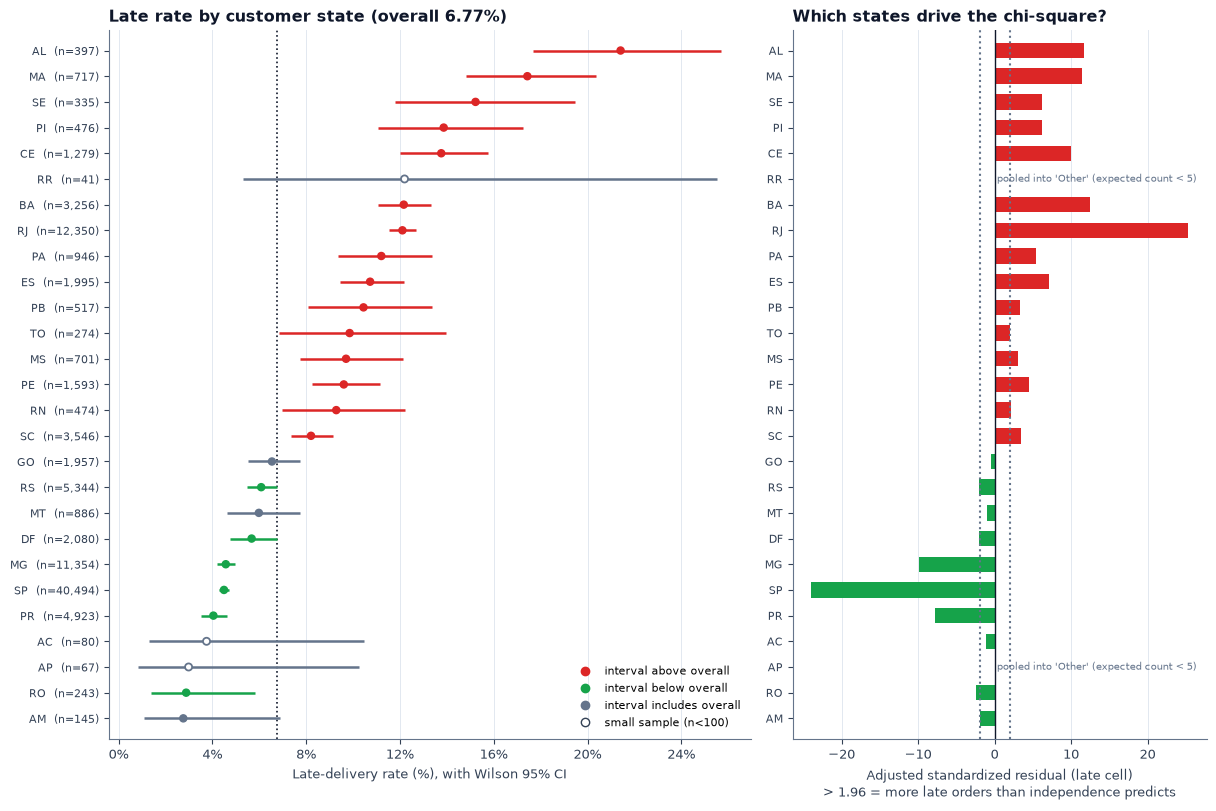

In [9]:
# ---- Figure 21: late rate by customer state (Wilson CI) + adjusted standardized residuals --------------
res_map = dict(zip(CHI["customer_state"]["level_summary"]["level"], CHI["customer_state"]["level_summary"]["adj_residual"]))
order = st.copy()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 8.2), gridspec_kw={"width_ratios": [1.55, 1]}, sharey=False)
forest(ax, order, "customer_state", BASE)
ax.set_xlabel("Late-delivery rate (%), with Wilson 95% CI")
ax.set_title(f"Late rate by customer state (overall {pct(BASE)})")
ax.plot([], [], "o", color=P["red"], label="interval above overall")
ax.plot([], [], "o", color=P["green"], label="interval below overall")
ax.plot([], [], "o", color=P["slate_light"], label="interval includes overall")
ax.plot([], [], "o", mfc="white", mec=P["slate"], label=f"small sample (n<{MIN_N})")
ax.legend(loc="lower right", fontsize=8)
y = np.arange(len(order))[::-1]
vals = order["customer_state"].map(res_map).to_numpy(dtype=float)
cols_r = np.where(vals > 0, P["red"], P["green"])
ax2.barh(y[np.isfinite(vals)], vals[np.isfinite(vals)], color=cols_r[np.isfinite(vals)], height=0.6)
for yi, v, s_ in zip(y, vals, order["customer_state"]):
    if not np.isfinite(v):
        ax2.text(0.3, yi, "pooled into 'Other' (expected count < 5)", va="center", fontsize=7.5, color=P["slate_light"])
ax2.axvline(0, color=P["navy"], lw=1); ax2.axvline(1.96, color=P["slate_light"], ls=":"); ax2.axvline(-1.96, color=P["slate_light"], ls=":")
ax2.set_yticks(y); ax2.set_yticklabels(order["customer_state"], fontsize=8); ax2.set_ylim(-0.8, len(order) - 0.2)
ax2.set_xlabel("Adjusted standardized residual (late cell)\n> 1.96 = more late orders than independence predicts")
ax2.set_title("Which states drive the chi-square?"); ax2.grid(axis="y", visible=False)
save_show(fig, "21_regional_late_rate_and_residuals")

In [10]:
# ---- state-vs-rest proportion tests (Newcombe CI + pooled z) with Holm correction, reliable states only -------
def vs_rest(tab: pd.DataFrame, key: str, total_k: int = K_LATE, total_n: int = N, only_reliable: bool = True) -> pd.DataFrame:
    t = tab[tab["reliable"]] if only_reliable else tab
    rows = []
    for _, r in t.iterrows():
        k, n = int(r["n_late"]), int(r["n_orders"])
        diff = sa.proportion_diff_ci(k, n, total_k - k, total_n - n)
        z = sa.two_proportion_ztest(k, n, total_k - k, total_n - n)
        rows.append({key: r[key], "n": n, "late_%": 100 * k / n, "rest_%": 100 * (total_k - k) / (total_n - n),
                     "diff_pp": 100 * diff["diff"], "CI_low_pp": 100 * diff["ci_low"], "CI_high_pp": 100 * diff["ci_high"],
                     "p_raw": z["p_value"]})
    out = pd.DataFrame(rows)
    out["p_holm"] = sa.holm_adjust(out["p_raw"].to_numpy())
    out["sig_raw"] = out["p_raw"] < ALPHA
    out["sig_holm"] = out["p_holm"] < ALPHA
    return out.sort_values("diff_pp", ascending=False).reset_index(drop=True)

state_vs_rest = vs_rest(st, "customer_state")
m = len(state_vs_rest)
print(f"{m} states with n >= {MIN_N} were each compared with all other orders: "
      f"{int(state_vs_rest.sig_raw.sum())} differ at unadjusted p < {ALPHA}; "
      f"{int(state_vs_rest.sig_holm.sum())} survive Holm adjustment for {m} comparisons "
      f"({int((state_vs_rest.sig_raw & ~state_vs_rest.sig_holm).sum())} do not).")
tbl = state_vs_rest.copy()
tbl["p_raw"] = tbl["p_raw"].map(fmt_p); tbl["p_holm"] = tbl["p_holm"].map(fmt_p)
display(tbl.round(2))

24 states with n >= 100 were each compared with all other orders: 21 differ at unadjusted p < 0.05; 16 survive Holm adjustment for 24 comparisons (5 do not).


,customer_state,n,late_%,rest_%,diff_pp,CI_low_pp,CI_high_pp,p_raw,p_holm,sig_raw,sig_holm
0,AL,397,21.4100,6.7100,14.7000,10.9400,19.0000,2.89e-31,6.07e-30,True,True
1,MA,717,17.4300,6.6900,10.7400,8.1300,13.6900,4.06e-30,8.13e-29,True,True
2,SE,335,15.2200,6.7400,8.4800,5.0300,12.7200,7.00e-10,1.00e-08,True,True
3,PI,476,13.8700,6.7400,7.1300,4.3100,10.5300,6.69e-10,1.00e-08,True,True
4,CE,1279,13.7600,6.6800,7.0800,5.2900,9.0800,1.36e-23,2.58e-22,True,True
5,RJ,12350,12.1100,5.9900,6.1200,5.5300,6.7200,1.04e-140,2.49e-139,True,True
6,BA,3256,12.1600,6.5800,5.5800,4.4900,6.7600,1.41e-35,3.10e-34,True,True
7,PA,946,11.2100,6.7300,4.4800,2.6100,6.6500,4.99e-08,6.49e-07,True,True
8,ES,1995,10.7300,6.6900,4.0400,2.7400,5.4800,1.23e-12,1.97e-11,True,True
9,PB,517,10.4400,6.7500,3.6900,1.3400,6.6300,8.64e-04,0.0086,True,True


In [11]:
# Two named contrasts that dominate the volume: Rio de Janeiro vs Sao Paulo (both large, both well measured)
def named_contrast(a, b, col="customer_state"):
    ka, na = int(d.loc[d[col] == a, "late"].sum()), int((d[col] == a).sum())
    kb, nb = int(d.loc[d[col] == b, "late"].sum()), int((d[col] == b).sum())
    diff = sa.proportion_diff_ci(ka, na, kb, nb); z = sa.two_proportion_ztest(ka, na, kb, nb)
    return dict(a=a, b=b, ka=ka, na=na, kb=kb, nb=nb, **{k: diff[k] for k in ("p1", "p2", "diff", "ci_low", "ci_high")}, p=z["p_value"])

RJ_SP = named_contrast("RJ", "SP")
print(f"RJ: {RJ_SP['ka']:,}/{RJ_SP['na']:,} late = {pct(RJ_SP['p1'])}   SP: {RJ_SP['kb']:,}/{RJ_SP['nb']:,} late = {pct(RJ_SP['p2'])}")
print(f"difference RJ - SP = {100 * RJ_SP['diff']:+.2f} pp, Newcombe 95% CI {100 * RJ_SP['ci_low']:+.2f} to {100 * RJ_SP['ci_high']:+.2f} pp, p {fmt_p(RJ_SP['p'])}")

RJ: 1,495/12,350 late = 12.11%   SP: 1,820/40,494 late = 4.49%
difference RJ - SP = +7.61 pp, Newcombe 95% CI +7.01 to +8.23 pp, p 9.22e-205


In [12]:
# ---- Is a state's late rate just a long-distance story?  (descriptive, state level, ecological) -----------------
sr = st[st["reliable"]].copy()
sr["mean_promise_days"] = sr["customer_state"].map(d.groupby("customer_state", observed=True)["estimated_delivery_days"].mean())
sr["same_state_share"] = sr["customer_state"].map(d.groupby("customer_state", observed=True)["same_state"].mean())
rho_dur = stats.spearmanr(sr["late_rate"], sr["median_duration"])
rho_same = stats.spearmanr(sr["late_rate"], sr["same_state_share"])
rho_prom = stats.spearmanr(sr["late_rate"], sr["mean_promise_days"])
print(f"Across the {len(sr)} reliable states (state-level, n = {len(sr)} points):")
print(f"  late rate vs median delivery duration : Spearman rho = {rho_dur.statistic:+.3f} (p = {rho_dur.pvalue:.3g})")
print(f"  late rate vs share of same-state orders: Spearman rho = {rho_same.statistic:+.3f} (p = {rho_same.pvalue:.3g})")
print(f"  late rate vs mean promised delivery days: Spearman rho = {rho_prom.statistic:+.3f} (p = {rho_prom.pvalue:.3g})")
sr[["customer_state", "n_orders", "late_rate", "median_duration", "mean_promise_days", "same_state_share"]].head(8).round(3)

Across the 24 reliable states (state-level, n = 24 points):
  late rate vs median delivery duration : Spearman rho = +0.475 (p = 0.0191)
  late rate vs share of same-state orders: Spearman rho = -0.313 (p = 0.136)
  late rate vs mean promised delivery days: Spearman rho = +0.210 (p = 0.324)


,customer_state,n_orders,late_rate,median_duration,mean_promise_days,same_state_share
0,AL,397,0.2140,22.3330,33.2090,0.0000
1,MA,717,0.1740,19.1910,31.0840,0.0200
2,SE,335,0.1520,18.0140,31.4840,0.0000
3,PI,476,0.1390,16.2920,30.7020,0.0020
4,CE,1279,0.1380,18.2090,32.0050,0.0070
6,BA,3256,0.1220,16.9140,30.0730,0.0200
7,RJ,12350,0.1210,12.0420,26.9980,0.0770
8,PA,946,0.1120,21.0780,37.7920,0.0000


### Interpretation of RQ1

**Result.** Late rates differ clearly between regions: chi-square test, V = 0.136 (bias-corrected 0.135), a **small** effect by Cohen's convention, and far beyond chance (p < 1e-300). Among states with at least 100 orders
the rate runs from **AM (2.8%, n = 145)** to **AL (21.4%, n = 397)**, against an overall rate of 6.77%. Rio de Janeiro (RJ, 12.1%, n = 12,350) is the large state that stands out most, versus São Paulo (SP, 4.5%, n = 40,494): a difference of +7.6 percentage points
(Newcombe 95% CI +7.0 to +8.2).
Of the 24 states with n >= 100, 21 differ from the rest of the data at the unadjusted 5% level and **16** remain after Holm's correction for 24 comparisons; the states that lose significance
after correction are DF, RN, RO, RS, TO (their intervals are wide or their rates close to the overall rate). The adjusted residuals show that the chi-square statistic is driven mostly by SP, MG and PR (fewer late orders than expected) and by RJ, BA and the north-eastern states (more).

**How to read it.** Delivery *duration* differs substantially by state (Kruskal-Wallis epsilon-squared = 0.25, a **medium** effect), while *lateness*, which compares the duration with the promise shown at checkout, differs less (V = 0.136, small; the two effect sizes are on different scales, so this is a qualitative contrast).
At state level, late rate and median duration are positively rank-correlated (rho = +0.475, only 24 points), and the correlation of late rate with the share of same-state orders (rho = -0.313, p = 0.14) is not distinguishable from zero with so few points.
This is an ecological comparison of states, not of orders, so it can only be suggestive.

**Caution.** (1) The interval for each state is an *unadjusted* Wilson interval; with 24 states, a few will exclude the overall rate by chance alone. (2) The state differences are mixed with **time**: the three spike months of section 6 hold a disproportionate share of late orders, and the regional V falls to 0.106 when they are removed (section 8) but remains a small, clearly non-zero effect.
(3) This is association only: the data contain no distance, carrier, road or weather variables, so *why* a region is later cannot be read from them.

## 3. RQ2 — Does the late-delivery rate differ between product categories?

**H0:** the late probability is the same in every product category. **H1:** at least one category differs.

Each order is assigned the category of its highest-priced item. With many categories, small ones give noisy rates, so the ranking uses only categories with n >= 100 and
the chi-square test pools categories whose expected counts would fall below 5. The chart shows the ten highest and ten lowest rates with their intervals and sample sizes.

**Missing categories are not a category.** 1,358 orders (1.4% of all, late rate 7.1%) have no product category in the source data; the data layer labels them `unknown`. That label is a missing-data bucket, not a product, so it is **left out of every RQ2 test and ranking**
(chi-square, the n >= 100 ranking and the category-vs-rest comparisons, whose comparison group is all other orders of known category). RQ2 therefore rests on 95,112 orders, and the category counts below (and in the dashboard's insights) exclude it. All other sections keep these orders.

In [13]:
cp = an.category_performance(d_cat, min_orders=MIN_N).sort_values("late_rate", ascending=False).reset_index(drop=True)
rel_cat = cp[cp["reliable"]].reset_index(drop=True)
print(f"{len(cp)} product categories observed (the {N_UNKNOWN:,} orders with a missing category are not a category and are left out); "
      f"{len(rel_cat)} have n >= {MIN_N}; {len(cp) - len(rel_cat)} are small samples and excluded from rankings.")
ext = pd.concat([rel_cat.head(10), rel_cat.tail(10)]).reset_index(drop=True)
view = ext[["product_category", "n_orders", "n_late", "late_rate", "late_ci_low", "late_ci_high", "median_duration", "mean_freight"]].copy()
for c in ["late_rate", "late_ci_low", "late_ci_high"]:
    view[c] = (100 * view[c]).round(2)
view.rename(columns={"late_rate": "late_%", "late_ci_low": "CI_low_%", "late_ci_high": "CI_high_%"})

73 product categories observed (the 1,358 orders with a missing category are not a category and are left out); 51 have n >= 100; 22 are small samples and excluded from rankings.


,product_category,n_orders,n_late,late_%,CI_low_%,CI_high_%,median_duration,mean_freight
0,audio,344,41,11.9200,8.9100,15.7700,10.7798,16.4151
1,home_confort,370,35,9.4600,6.8800,12.8700,11.5033,23.5968
2,fashion_underwear_beach,117,11,9.4000,5.3300,16.0500,11.1699,15.8468
3,books_technical,254,21,8.2700,5.4700,12.3100,8.9513,16.4731
4,baby,2761,224,8.1100,7.1500,9.1900,10.0731,24.1491
5,office_furniture,1251,101,8.0700,6.6900,9.7100,18.8745,53.6664
6,christmas_supplies,124,10,8.0600,4.4400,14.2100,13.0780,25.5625
7,electronics,2502,192,7.6700,6.6900,8.7800,11.0234,18.2737
8,furniture_living_room,409,31,7.5800,5.3900,10.5600,12.0711,44.0881
9,musical_instruments,608,46,7.5700,5.7200,9.9400,10.4180,29.4097


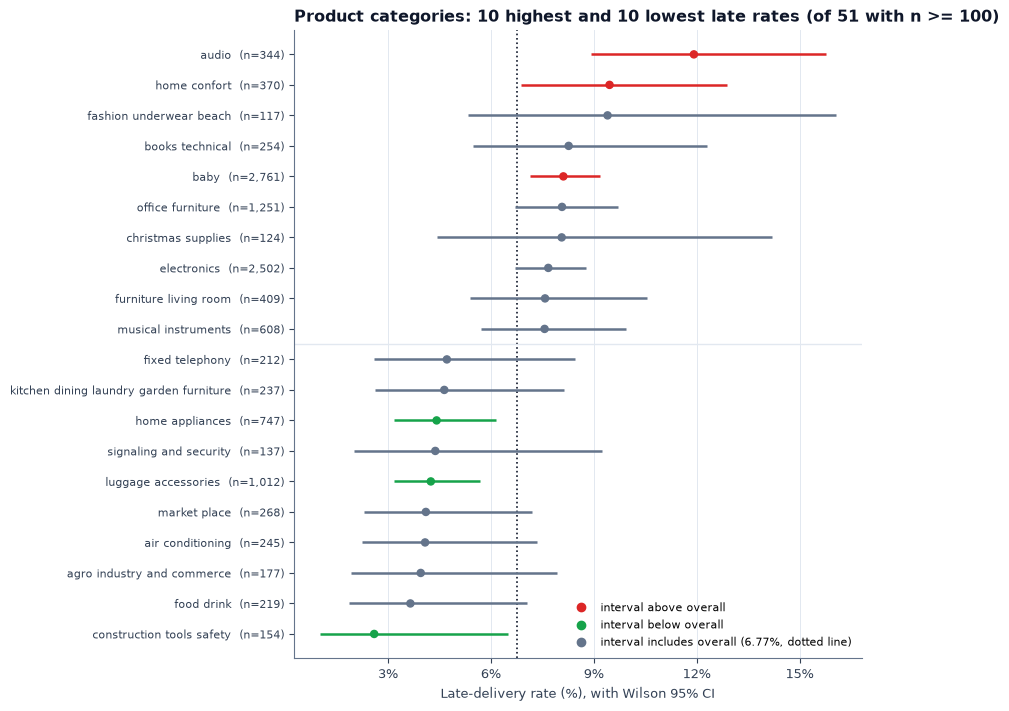

In [14]:
# ---- Figure 22: extremes of the category ranking (reliable categories only) -------------------------------------
fig, ax = plt.subplots(figsize=(8.8, 7.2))
forest(ax, ext, "product_category", BASE_CAT, label_fmt=lambda s: s.replace("_", " "))
ax.axhline(9.5, color=P["border"], lw=1)
ax.set_xlabel("Late-delivery rate (%), with Wilson 95% CI")
ax.set_title(f"Product categories: 10 highest and 10 lowest late rates (of {len(rel_cat)} with n >= {MIN_N})")
ax.plot([], [], "o", color=P["red"], label="interval above overall"); ax.plot([], [], "o", color=P["green"], label="interval below overall")
ax.plot([], [], "o", color=P["slate_light"], label=f"interval includes overall ({pct(BASE_CAT)}, dotted line)")
ax.legend(loc="lower right", fontsize=8)
save_show(fig, "22_category_late_rate_extremes")

In [15]:
# ---- chi-square result, residual leaders, and category-vs-rest with Holm ----------------------------------------
s = CHI["product_category"]
print(f"chi2 = {s['chi2']:.1f}, dof = {s['dof']}, p = {fmt_p(s['p_value'])}, n = {s['n']:,}, levels tested = {s['n_levels_tested']} "
      f"(of {s['n_levels_original']}), Cramer's V = {s['cramers_v']:.4f} [{s['effect_label']}], bias-corrected V = {s['cramers_v_corrected']:.4f} "
      f"(bootstrap 95% CI {VCI['product_category'][0]:.3f} to {VCI['product_category'][1]:.3f})")
display(s["level_summary"].head(8).assign(late_rate=lambda t: (100 * t.late_rate).round(2)).rename(columns={"late_rate": "late_%"}).round(2))

cat_vs_rest = vs_rest(cp, "product_category", total_k=K_CAT, total_n=N_CAT)
mc = len(cat_vs_rest)
print(f"\n{mc} categories with n >= {MIN_N} compared with all other orders of known category: {int(cat_vs_rest.sig_raw.sum())} differ at unadjusted p < {ALPHA}; "
      f"{int(cat_vs_rest.sig_holm.sum())} survive Holm adjustment for {mc} comparisons.")
tbl = cat_vs_rest[cat_vs_rest.sig_holm].copy()
tbl["p_raw"] = tbl["p_raw"].map(fmt_p); tbl["p_holm"] = tbl["p_holm"].map(fmt_p)
display(tbl.round(2))

chi2 = 144.6, dof = 54, p = 3.27e-10, n = 95,112, levels tested = 55 (of 73), Cramer's V = 0.0390 [negligible], bias-corrected V = 0.0309 (bootstrap 95% CI 0.024 to 0.038)


,level,n,n_late,late_%,adj_residual
0,housewares,5680,308,5.4200,-4.1600
1,audio,344,41,11.9200,3.8100
2,luggage_accessories,1012,43,4.2500,-3.2100
3,health_beauty,8613,649,7.5400,2.9700
4,bed_bath_table,9184,687,7.4800,2.8600
5,baby,2761,224,8.1100,2.8600
6,pet_shop,1682,85,5.0500,-2.8200
7,home_appliances,747,33,4.4200,-2.5700



51 categories with n >= 100 compared with all other orders of known category: 13 differ at unadjusted p < 0.05; 2 survive Holm adjustment for 51 comparisons.


,product_category,n,late_%,rest_%,diff_pp,CI_low_pp,CI_high_pp,p_raw,p_holm,sig_raw,sig_holm
0,audio,344,11.9200,6.7500,5.1700,2.1500,9.0200,1.39e-04,0.0069,True,True
35,housewares,5680,5.4200,6.8500,-1.4300,-2.0100,-0.7900,3.15e-05,0.0016,True,True


In [16]:
# ---- confounding probe: does the category association survive inside the biggest state (Sao Paulo customers)? ---
sp_only = d[d["customer_state"] == "SP"]
s_sp = sa.chi_square_test(sp_only[sp_only["product_category"] != UNKNOWN_CAT], "product_category", "late")
print(f"SP customers only (n = {s_sp['n']:,}): chi2 = {s_sp['chi2']:.1f}, dof = {s_sp['dof']}, p = {fmt_p(s_sp['p_value'])}, "
      f"Cramer's V = {s_sp['cramers_v']:.4f} [{s_sp['effect_label']}]   (all states: V = {CHI['product_category']['cramers_v']:.4f})")
cat_state_mix = (d_cat.groupby("product_category", observed=True)["same_state"].mean().rename("same_state_share").to_frame()
                 .join(cp.set_index("product_category")["n_orders"]).query("n_orders >= @MIN_N"))
print(f"Same-state share varies across categories from {pct(cat_state_mix.same_state_share.min())} to {pct(cat_state_mix.same_state_share.max())} "
      f"- categories differ in seller/customer geography, which is a confounder for any category comparison.")

SP customers only (n = 39,944): chi2 = 76.7, dof = 35, p = 6.00e-05, Cramer's V = 0.0438 [negligible]   (all states: V = 0.0390)
Same-state share varies across categories from 16.95% to 54.13% - categories differ in seller/customer geography, which is a confounder for any category comparison.


### Interpretation of RQ2

**Result.** The association is statistically detectable (chi-square p = 3.3e-10) but **negligible in size**: V = 0.039, or 0.031 after bias correction (the plain V is inflated when a table has many cells; bootstrap 95% CI for the corrected V 0.024 to 0.038). Among the 51 categories with n >= 100 (of 73 observed product categories, not counting the missing-category bucket) late rates range from 2.6% to 11.9% — but most of that range is noise-width:
only 13 categories differ from all other orders at the unadjusted 5% level, and just **2** survive Holm's correction for 51 comparisons: **audio, housewares**. For the rest the data cannot distinguish the category's rate from the overall rate.

**Confounding.** Categories differ in who sells and ships them: the share of same-state orders ranges from 17% to 54% across categories, so a category comparison partly compares geographies. The category effect does not disappear inside the largest destination state (São Paulo customers only: V = 0.044, still negligible), but we cannot separate a product effect from seller, route and period effects with this data.

**Practical meaning.** Product category alone is a weak guide to delivery risk. In the dashboard, category rankings should be read together with n and the interval, and the categories flagged in section 3 are a *shortlist to investigate*, not a verdict.

## 4. RQ3 — Same-state versus cross-state orders

**H0:** the late probability is the same for same-state and cross-state orders (and delivery durations come from the same distribution). **H1:** they differ.

*Same-state* means the representative seller (the seller with the largest item value in the order) and the customer are in the same state. We estimate the size of the difference with an interval, test it three ways (Newcombe interval, pooled z-test, chi-square) and confirm
that they agree, then look at delivery duration.

In [17]:
ss = an.same_state_comparison(d, min_orders=MIN_N).set_index("group")
same, cross = ss.loc["same_state"], ss.loc["cross_state"]
k1, n1, k0, n0 = int(same.n_late), int(same.n_orders), int(cross.n_late), int(cross.n_orders)
view = ss[["n_orders", "n_late", "late_rate", "late_ci_low", "late_ci_high", "median_duration", "mean_duration"]].copy()
for c in ["late_rate", "late_ci_low", "late_ci_high"]:
    view[c] = (100 * view[c]).round(2)
display(view.rename(columns={"late_rate": "late_%", "late_ci_low": "CI_low_%", "late_ci_high": "CI_high_%"}))

# proportion difference: src (Newcombe) vs independent Newcombe + pooled z + scipy chi-square 2x2
diff = sa.proportion_diff_ci(k1, n1, k0, n0)
def wil(k, n, z=ZC):
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h
l1, u1 = wil(k1, n1); l0, u0 = wil(k0, n0); p1, p0 = k1 / n1, k0 / n0
nc_lo = (p1 - p0) - math.sqrt((p1 - l1) ** 2 + (u0 - p0) ** 2)
nc_hi = (p1 - p0) + math.sqrt((u1 - p1) ** 2 + (p0 - l0) ** 2)
pooled = (k1 + k0) / (n1 + n0)
z_manual = (p1 - p0) / math.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n0))
zt = sa.two_proportion_ztest(k1, n1, k0, n0)
tab2 = np.array([[k1, n1 - k1], [k0, n0 - k0]])
chi2_2x2, p_2x2, _, _ = stats.chi2_contingency(tab2, correction=False)
print(f"same-state minus cross-state late rate = {100 * diff['diff']:+.2f} pp; Newcombe 95% CI (src) {100 * diff['ci_low']:+.2f} to {100 * diff['ci_high']:+.2f}; "
      f"(by hand) {100 * nc_lo:+.2f} to {100 * nc_hi:+.2f}")
print(f"pooled z (src) = {zt['z']:+.3f}; (by hand) = {z_manual:+.3f}; z^2 = {z_manual ** 2:.3f}  vs  scipy chi-square (2x2, no correction) = {chi2_2x2:.3f}")
assert abs(diff["ci_low"] - nc_lo) < 1e-9 and abs(diff["ci_high"] - nc_hi) < 1e-9 and abs(z_manual ** 2 - chi2_2x2) < 1e-6
assert abs(zt["z"] - z_manual) < 1e-9 and abs(MAN["same_state"]["chi2"] - chi2_2x2) < 1e-6

# effect measures: risk ratio and odds ratio with CIs, Fisher exact test
rr = p1 / p0
se_rr = math.sqrt(1 / k1 - 1 / n1 + 1 / k0 - 1 / n0)
OR_crude, or_lo, or_hi = or_table(k1, n1 - k1, k0, n0 - k0)
fisher = stats.fisher_exact(tab2)
print(f"risk ratio (same / cross) = {rr:.3f} (95% CI {math.exp(math.log(rr) - ZC * se_rr):.3f} to {math.exp(math.log(rr) + ZC * se_rr):.3f}); "
      f"odds ratio = {OR_crude:.3f} (95% CI {or_lo:.3f} to {or_hi:.3f}); Fisher exact p = {fmt_p(max(fisher.pvalue, P_FLOOR))}, scipy OR = {fisher.statistic:.3f}")

,n_orders,n_late,late_%,CI_low_%,CI_high_%,median_duration,mean_duration
group,,,,,,,
cross_state,61774,4971,8.0500,7.8400,8.2600,12.7881,15.1495
same_state,34696,1563,4.5000,4.2900,4.7300,6.5451,7.9447


same-state minus cross-state late rate = -3.54 pp; Newcombe 95% CI (src) -3.85 to -3.23; (by hand) -3.85 to -3.23
pooled z (src) = -21.012; (by hand) = -21.012; z^2 = 441.488  vs  scipy chi-square (2x2, no correction) = 441.488
risk ratio (same / cross) = 0.560 (95% CI 0.530 to 0.592); odds ratio = 0.539 (95% CI 0.508 to 0.571); Fisher exact p = 9.80e-104, scipy OR = 0.539


In [18]:
# ---- delivery duration: Mann-Whitney (src and scipy), with a bootstrap CI for the difference in medians -----------
mw = sa.kruskal_or_mannwhitney(d, "delivery_duration_days", "same_state")
x_cross = d.loc[d.same_state == 0, "delivery_duration_days"].to_numpy()
x_same = d.loc[d.same_state == 1, "delivery_duration_days"].to_numpy()
u, p_u = stats.mannwhitneyu(x_cross, x_same, alternative="two-sided")
rb = 2 * u / (len(x_cross) * len(x_same)) - 1            # rank-biserial: > 0 means cross-state tends to be LONGER
print(f"Mann-Whitney (src): U = {mw['statistic']:.0f}, p = {fmt_p(mw['p_value'])}, rank-biserial = {mw['effect_size']:+.3f} [{mw['effect_label']}] "
      f"(first level = same_state=0 i.e. cross-state)")
print(f"Mann-Whitney (scipy direct): U = {u:.0f}, p = {fmt_p(max(p_u, P_FLOOR))}, rank-biserial = {rb:+.3f}")
assert abs(u - mw["statistic"]) < 1e-6 and abs(rb - mw["effect_size"]) < 1e-9
rng = np.random.default_rng(SEED)
B = 500
dm = np.array([np.median(rng.choice(x_cross, len(x_cross))) - np.median(rng.choice(x_same, len(x_same))) for _ in range(B)])
MED_DIFF = float(np.median(x_cross) - np.median(x_same))
MED_DIFF_CI = (float(np.percentile(dm, 2.5)), float(np.percentile(dm, 97.5)))
print(f"median duration: cross-state {np.median(x_cross):.2f} d (n={len(x_cross):,}) vs same-state {np.median(x_same):.2f} d (n={len(x_same):,}); "
      f"difference {MED_DIFF:+.2f} d, bootstrap 95% CI {MED_DIFF_CI[0]:+.2f} to {MED_DIFF_CI[1]:+.2f} ({B} resamples)")
log_test("RQ3", "Mann-Whitney duration by same_state", "mann-whitney", mw["n"], mw["p_value"], "rank-biserial", mw["effect_size"], mw["effect_label"])

Mann-Whitney (src): U = 1709892180, p = < 1e-300, rank-biserial = +0.596 [large] (first level = same_state=0 i.e. cross-state)
Mann-Whitney (scipy direct): U = 1709892180, p = < 1e-300, rank-biserial = +0.596


median duration: cross-state 12.79 d (n=61,774) vs same-state 6.55 d (n=34,696); difference +6.24 d, bootstrap 95% CI +6.10 to +6.35 (500 resamples)


### Is the same-state difference a geography artefact? Stratifying by customer state

A crude comparison of same-state and cross-state orders mixes very different customer regions: 88.6% of all same-state orders are São Paulo to São Paulo, and São Paulo is also the state with the lowest late rate in section 2.
To ask whether the difference survives comparing like with like, the comparison is repeated **inside each customer state** and combined with the **Mantel-Haenszel** odds ratio (Robins-Breslow-Greenland interval). Only 6 states have at least 100 orders in both groups, so the stratum-level results are shown for those.

In [19]:
# ---- Mantel-Haenszel: same_state x late, stratified by customer_state (adjusts for destination region) ----------
strata = []
for s_, g in d.groupby("customer_state", observed=True):
    a_ = int(((g.same_state == 1) & (g.late == 1)).sum()); b_ = int(((g.same_state == 1) & (g.late == 0)).sum())
    c_ = int(((g.same_state == 0) & (g.late == 1)).sum()); d_ = int(((g.same_state == 0) & (g.late == 0)).sum())
    strata.append((s_, a_, b_, c_, d_))
S = pd.DataFrame(strata, columns=["customer_state", "a_same_late", "b_same_ok", "c_cross_late", "d_cross_ok"])
S["n"] = S[["a_same_late", "b_same_ok", "c_cross_late", "d_cross_ok"]].sum(axis=1)
S["n_same"] = S.a_same_late + S.b_same_ok; S["n_cross"] = S.c_cross_late + S.d_cross_ok
inform = S[(S.n_same > 0) & (S.n_cross > 0)].copy()                     # strata that contain both groups
R = (inform.a_same_late * inform.d_cross_ok / inform.n).sum()
Sx = (inform.b_same_ok * inform.c_cross_late / inform.n).sum()
OR_MH = R / Sx
# Robins-Breslow-Greenland variance of log(OR_MH)
P_ = (inform.a_same_late + inform.d_cross_ok) / inform.n; Q_ = (inform.b_same_ok + inform.c_cross_late) / inform.n
Rk = inform.a_same_late * inform.d_cross_ok / inform.n; Sk = inform.b_same_ok * inform.c_cross_late / inform.n
var = (P_ * Rk).sum() / (2 * R ** 2) + ((P_ * Sk + Q_ * Rk).sum()) / (2 * R * Sx) + (Q_ * Sk).sum() / (2 * Sx ** 2)
OR_MH_CI = (math.exp(math.log(OR_MH) - ZC * math.sqrt(var)), math.exp(math.log(OR_MH) + ZC * math.sqrt(var)))
# MH chi-square test of OR = 1 (no continuity correction)
E_a = (inform.n_same * (inform.a_same_late + inform.c_cross_late) / inform.n)
V_a = (inform.n_same * inform.n_cross * (inform.a_same_late + inform.c_cross_late) * (inform.b_same_ok + inform.d_cross_ok)
       / (inform.n ** 2 * (inform.n - 1)))
chi2_mh = (inform.a_same_late.sum() - E_a.sum()) ** 2 / V_a.sum()
p_mh = max(float(stats.chi2.sf(chi2_mh, 1)), P_FLOOR)
print(f"{len(inform)} of {len(S)} customer states contain both same-state and cross-state orders.")
print(f"Crude odds ratio (late, same vs cross)            : {OR_crude:.3f}  (95% CI {or_lo:.3f} to {or_hi:.3f})")
print(f"Mantel-Haenszel odds ratio, adjusted for state     : {OR_MH:.3f}  (95% CI {OR_MH_CI[0]:.3f} to {OR_MH_CI[1]:.3f}); MH chi2 = {chi2_mh:.1f}, p = {fmt_p(p_mh)}")
print(f"Share of the crude log-odds difference that remains after adjustment: {math.log(OR_MH) / math.log(OR_crude):.1%}")

big = inform[(inform.n_same >= MIN_N) & (inform.n_cross >= MIN_N)].copy()
orw = big.apply(lambda r: pd.Series(or_table(r.a_same_late, r.b_same_ok, r.c_cross_late, r.d_cross_ok), index=["OR", "lo", "hi"]), axis=1)
big = pd.concat([big, orw], axis=1)
big["late_same_%"] = 100 * big.a_same_late / big.n_same; big["late_cross_%"] = 100 * big.c_cross_late / big.n_cross
big = big.sort_values("n", ascending=False).reset_index(drop=True)
print(f"\nStrata with n >= {MIN_N} in BOTH groups ({len(big)} states): same-state odds ratio below 1 in {(big.OR < 1).sum()}, above 1 in {(big.OR > 1).sum()}")
display(big[["customer_state", "n_same", "n_cross", "late_same_%", "late_cross_%", "OR", "lo", "hi"]].round(3))

17 of 27 customer states contain both same-state and cross-state orders.
Crude odds ratio (late, same vs cross)            : 0.539  (95% CI 0.508 to 0.571)
Mantel-Haenszel odds ratio, adjusted for state     : 0.826  (95% CI 0.756 to 0.903); MH chi2 = 15.8, p = 7.09e-05
Share of the crude log-odds difference that remains after adjustment: 30.8%

Strata with n >= 100 in BOTH groups (6 states): same-state odds ratio below 1 in 5, above 1 in 1


,customer_state,n_same,n_cross,late_same_%,late_cross_%,OR,lo,hi
0,SP,30727,9767,4.6470,4.0140,1.1660,1.0400,1.3070
1,RJ,954,11396,4.7170,12.7240,0.3400,0.2500,0.4600
2,MG,1527,9827,2.4890,4.8950,0.4960,0.3550,0.6930
3,RS,289,5055,2.7680,6.2710,0.4260,0.2090,0.8670
4,PR,714,4209,2.6610,4.2770,0.6120,0.3790,0.9880
5,SC,256,3290,4.2970,8.5110,0.4830,0.2610,0.8940


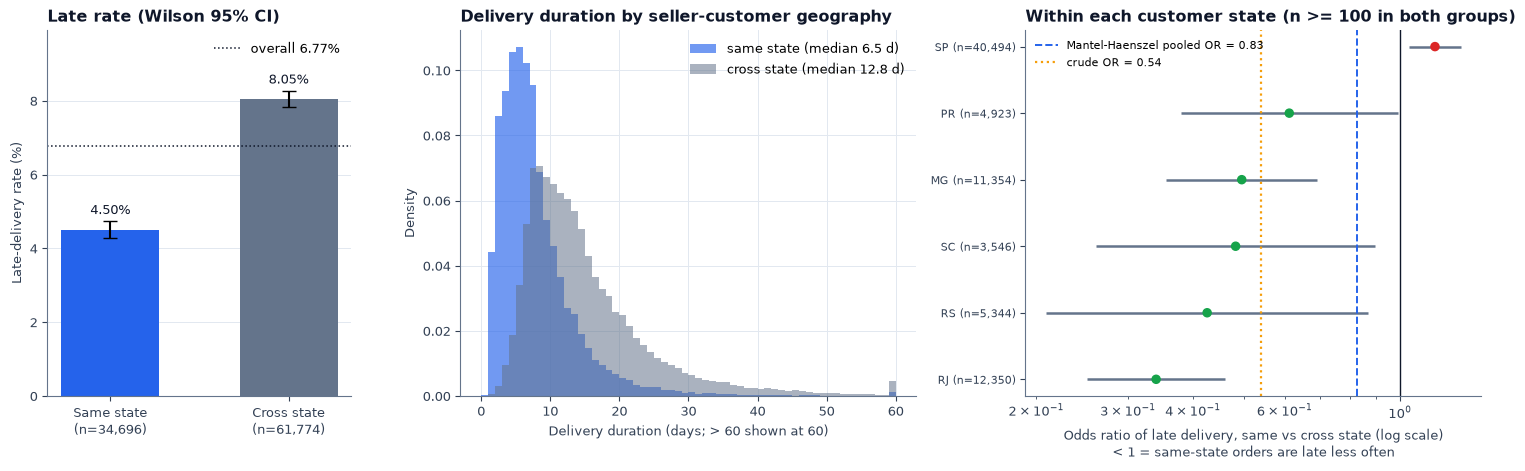

In [20]:
# ---- Figure 23: same vs cross state: late rate, duration distributions, and state-stratified odds ratios --------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [0.8, 1.2, 1.2]})
ax = axes[0]
labs = [f"Same state\n(n={n1:,})", f"Cross state\n(n={n0:,})"]
rates = np.array([p1, p0]) * 100
err = np.array([[p1 - l1, p0 - l0], [u1 - p1, u0 - p0]]) * 100
ax.bar(labs, rates, yerr=err, color=[P["blue"], P["slate_light"]], width=0.55, capsize=5)
for i, r_ in enumerate(rates):
    ax.text(i, r_ + err[1, i] + 0.2, f"{r_:.2f}%", ha="center", fontsize=9, color=P["navy"])
ax.axhline(BASE * 100, color=P["navy"], ls=":", lw=1.1, label=f"overall {pct(BASE)}")
ax.set_ylabel("Late-delivery rate (%)"); ax.set_title("Late rate (Wilson 95% CI)"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(rates + err[1]) * 1.2)

ax = axes[1]
bins = np.linspace(0, 60, 61)
ax.hist(np.clip(x_same, 0, 60), bins=bins, density=True, alpha=0.65, color=P["blue"], label=f"same state (median {np.median(x_same):.1f} d)")
ax.hist(np.clip(x_cross, 0, 60), bins=bins, density=True, alpha=0.55, color=P["slate_light"], label=f"cross state (median {np.median(x_cross):.1f} d)")
ax.set_xlabel("Delivery duration (days; > 60 shown at 60)"); ax.set_ylabel("Density")
ax.set_title("Delivery duration by seller-customer geography"); ax.legend()

ax = axes[2]
bg = big.sort_values("OR").reset_index(drop=True)
yy = np.arange(len(bg))
ax.hlines(yy, bg.lo, bg.hi, color=P["slate_light"], lw=1.8)
ax.scatter(bg.OR, yy, color=[P["red"] if o > 1 else P["green"] for o in bg.OR], s=34, zorder=3)
ax.axvline(1, color=P["navy"], lw=1)
ax.axvline(OR_MH, color=P["blue"], ls="--", lw=1.4, label=f"Mantel-Haenszel pooled OR = {OR_MH:.2f}")
ax.axvline(OR_crude, color=P["amber"], ls=":", lw=1.6, label=f"crude OR = {OR_crude:.2f}")
ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels([f"{s_} (n={int(n_):,})" for s_, n_ in zip(bg.customer_state, bg.n)], fontsize=8)
ax.set_xlabel("Odds ratio of late delivery, same vs cross state (log scale)\n< 1 = same-state orders are late less often")
ax.set_title(f"Within each customer state (n >= {MIN_N} in both groups)"); ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="y", visible=False)
save_show(fig, "23_same_vs_cross_state")
log_test("RQ3", "chi-square-2x2 / Mantel-Haenszel same_state x late | customer_state", "mantel-haenszel", int(inform.n.sum()), p_mh,
         "MH odds ratio", OR_MH, "adjusted for state")

,from,to (excl.),n same-state,late % same-state,n cross-state,late % cross-state,difference (pp),CI low (pp),CI high (pp)
window,,,,,,,,,
train,2017-01-01,2018-04-01,21697,4.6200,42356,9.7000,-5.0800,-5.4700,-4.6800
validation,2018-04-01,2018-07-01,7748,2.2800,11895,5.4100,-3.1200,-3.6400,-2.5900
test,2018-07-01,end of data,5165,7.4200,7342,2.9700,4.4500,3.6500,5.2800


Month by month from 2017-01 (20 months, n >= 100 in both groups): same-state orders have the HIGHER late rate in 5 of 20 months: 2017-02, 2017-05, 2017-06, 2018-07, 2018-08.


,late % same,n same,late % cross,n cross,gap (pp)
ym,,,,,
2017-02,3.4800,517,2.7300,1136,0.7500
2017-05,4.8000,1126,2.1500,2419,2.6500
2017-06,3.6200,1076,2.7200,2059,0.9000
2018-07,4.0900,2325,2.9500,3831,1.1400
2018-08,10.1400,2840,2.9900,3511,7.1500


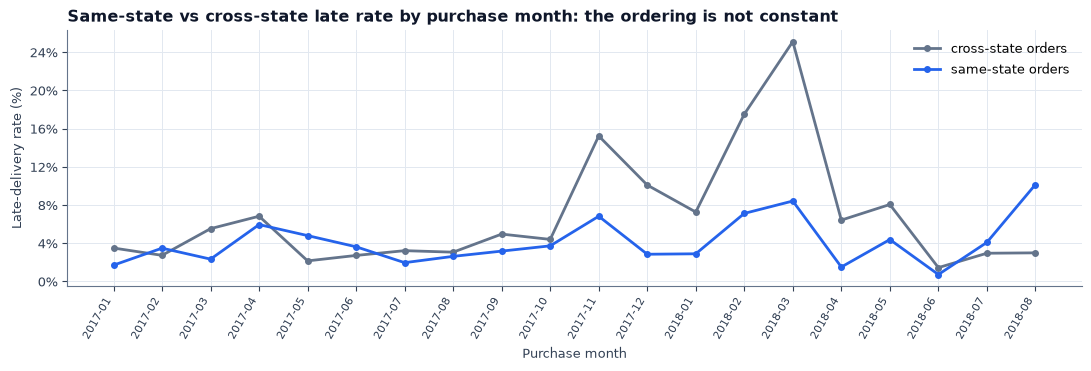

In [21]:
# ---- Is the same-state difference STABLE over time?  The pooled numbers above average over very different periods. ----
# Windows are the chronological train / validation / test windows of the prediction model (models/model_metrics.json),
# so this table can be compared directly with the model card in the app.
WIN = json.loads(config.MODEL_METRICS_PATH.read_text())["split"]["windows"]
ts = pd.to_datetime(d["order_purchase_timestamp"])
rows = []
for wname, (w0, w1) in WIN.items():
    wm = (ts >= pd.Timestamp(w0)) & ((ts < pd.Timestamp(w1)) if w1 else True)
    g1, g0 = d[wm & (d.same_state == 1)], d[wm & (d.same_state == 0)]
    k1_, n1_, k0_, n0_ = int(g1.late.sum()), len(g1), int(g0.late.sum()), len(g0)
    dw_ = sa.proportion_diff_ci(k1_, n1_, k0_, n0_)
    rows.append({"window": wname, "from": w0, "to (excl.)": w1 or "end of data", "n same-state": n1_, "late % same-state": 100 * k1_ / n1_,
                 "n cross-state": n0_, "late % cross-state": 100 * k0_ / n0_, "difference (pp)": 100 * dw_["diff"],
                 "CI low (pp)": 100 * dw_["ci_low"], "CI high (pp)": 100 * dw_["ci_high"]})
STAB = pd.DataFrame(rows).set_index("window")
display(STAB.round(2))

# the same comparison month by month (2017-01 onwards; every month has n >= MIN_N in both groups, checked below)
mo = (d[d.ym >= "2017-01"].groupby(["ym", "same_state"]).late.agg(["mean", "size"]).unstack("same_state"))
mo.columns = [f"{a}_{'same' if b == 1 else 'cross'}" for a, b in mo.columns]
mo["gap_pp"] = 100 * (mo["mean_same"] - mo["mean_cross"])
assert (mo[["size_same", "size_cross"]] >= MIN_N).all().all(), "a month has fewer than MIN_N orders in one group"
N_MONTHS, N_MONTHS_SAME_HIGHER = len(mo), int((mo.gap_pp > 0).sum())
print(f"Month by month from 2017-01 ({N_MONTHS} months, n >= {MIN_N} in both groups): same-state orders have the HIGHER late rate in "
      f"{N_MONTHS_SAME_HIGHER} of {N_MONTHS} months: {', '.join(mo.index[mo.gap_pp > 0])}.")
display((mo.loc[mo.gap_pp > 0, ["mean_same", "size_same", "mean_cross", "size_cross", "gap_pp"]]
         .assign(mean_same=lambda t: 100 * t.mean_same, mean_cross=lambda t: 100 * t.mean_cross)
         .rename(columns={"mean_same": "late % same", "size_same": "n same", "mean_cross": "late % cross", "size_cross": "n cross", "gap_pp": "gap (pp)"})).round(2))

fig, ax = plt.subplots(figsize=(11, 3.8))
xm_ = np.arange(len(mo))
ax.plot(xm_, 100 * mo.mean_cross, "o-", color=P["slate_light"], lw=2, ms=4, label="cross-state orders")
ax.plot(xm_, 100 * mo.mean_same, "o-", color=P["blue"], lw=2, ms=4, label="same-state orders")
ax.set_xticks(xm_); ax.set_xticklabels(mo.index, rotation=60, ha="right", fontsize=8)
ax.set_xlabel("Purchase month"); ax.set_ylabel("Late-delivery rate (%)")
ax.set_title("Same-state vs cross-state late rate by purchase month: the ordering is not constant")
ax.legend(); pct_axis(ax, "y"); plt.tight_layout(); plt.show()

### Interpretation of RQ3

**Result — the crude association is real but mostly not what it looks like.**
* Same-state orders are late **4.50%** of the time (n = 34,696), cross-state orders **8.05%** (n = 61,774): a difference of **-3.54 percentage points** (Newcombe 95% CI -3.85 to -3.23; crude odds ratio 0.54). Cramer's V is only 0.068 — a **negligible** effect size despite p = 5.1e-98.
* Durations differ much more: the median is **6.5 days** for same-state versus **12.8 days** for cross-state orders (difference of the medians 6.2 days; bootstrap interval in the output above), rank-biserial r = +0.60 (**large**). Orders shipped within a state arrive much sooner. That is expected, and it is not the same as being late: the estimated delivery time for cross-state orders is also much longer (mean 27.8 days against 18.2 days for same-state orders).
* **Adjusting for customer state shrinks the lateness association a lot**: the Mantel-Haenszel odds ratio is **0.83** (95% CI 0.76 to 0.90) against a crude 0.54. It stays below 1 — same-state orders are somewhat less often late even within a state — but in the largest stratum, São Paulo customers, the direction **reverses**: 4.65% late for same-state against 4.01% for cross-state orders.
  The odds ratio is below 1 in 5 of the 6 strata with enough data and above 1 in 1, so a single pooled number summarises heterogeneous behaviour; the pooled estimate should not be treated as a constant "same-state effect".
* Removing the three spike months of section 6 cuts the same-state V from 0.068 to 0.027: part of the crude difference is the *timing* of orders, not geography alone (section 8).
* **The pooled lateness gap is not stable over time, and it reverses at the end of the data.** The table and chart above split the same comparison by the model's chronological windows: same-state versus cross-state late rate is 4.6% versus 9.7% in the training window (gap -5.1 pp), 2.3% versus 5.4% in the validation window (-3.1 pp), but **7.4% versus 3.0% in the test window (July-August 2018; gap +4.4 pp, Newcombe 95% CI +3.6 to +5.3)**: the same-state orders are *later* there. Month by month from 2017-01, same-state orders have the higher late rate in 5 of 20 months (2017-02, 2017-05, 2017-06, 2018-07, 2018-08). This is the same non-stationarity as in RQ5, and it agrees with the model card in the app (the gap "changes sign between windows"). The pooled 2016-2018 gap is an average over regimes, not a constant property of same-state shipping.

**Take-away.** Same-state shipping is clearly faster. Over the full 2016-2018 period same-state orders were also somewhat less often late, but that headline gap is largely explained by *where* the customers are (and when they ordered), it varies a lot between states, and it is **not stable in time**: it reverses in the most recent months of the data, so it should not be read as a lasting "same-state advantage". Anyone reading the dashboard's same-state card should also see the duration gap, the effect size, this confounding and the time instability.

## 5. RQ4 — How are weight and freight related to delivery duration?

**H0:** the Spearman rank correlation between the variable and delivery duration is zero. **H1:** it is not.

Weight, freight, and duration are strongly right-skewed (a few very heavy, expensive or slow orders), so the rank-based Spearman correlation is used instead of Pearson's. For each correlation the table compares:
scipy's `spearmanr`, the project module's value, Pearson's correlation of the ranks (identical by definition), the Fisher-z interval, and a **bootstrap** interval from resampling orders. Then we look at the binary outcome, a *partial* correlation, and the pattern inside same-state and cross-state orders.
`estimated_delivery_days` (the promise shown at checkout) is added as a reference because it is known at purchase time, and `total_weight_g ~ total_freight` as a sanity check of how much freight reflects weight.

In [22]:
pairs = [("total_weight_g", "delivery_duration_days"), ("total_freight", "delivery_duration_days"),
         ("freight_ratio", "delivery_duration_days"), ("estimated_delivery_days", "delivery_duration_days"),
         ("total_weight_g", "total_freight")]
SPEAR = {}
for x_, y_ in pairs:
    SPEAR[(x_, y_)] = spearman_full(d, x_, y_, B=200 if y_ == "delivery_duration_days" else 0)

rows = []
for (x_, y_), r_ in SPEAR.items():
    srcr = sa.spearman_test(d, x_, y_)
    rows.append({"x": x_, "y": y_, "n pairs": r_["n"], "rho (scipy)": r_["rho"], "rho (src)": srcr["rho"],
                 "rho (Pearson on ranks)": r_["rho_pearson_on_ranks"],
                 "Fisher-z 95% CI (src)": f"{srcr['ci_low']:.3f} to {srcr['ci_high']:.3f}",
                 "Fisher-z CI (hand, classic SE)": f"{r_['ci_classic'][0]:.3f} to {r_['ci_classic'][1]:.3f}",
                 "bootstrap 95% CI": (f"{r_['ci_boot'][0]:.3f} to {r_['ci_boot'][1]:.3f}" if "ci_boot" in r_ else "-"),
                 "p": fmt_p(r_["p"]), "strength": strength(r_["rho"])})
    assert abs(srcr["rho"] - r_["rho"]) < 1e-10 and abs(r_["rho"] - r_["rho_pearson_on_ranks"]) < 1e-10
    assert abs(srcr["ci_low"] - r_["ci_bw"][0]) < 1e-9
    if y_ == "delivery_duration_days":
        log_test("RQ4", f"Spearman {x_} ~ {y_}", "spearman", r_["n"], r_["p"], "Spearman rho", r_["rho"], strength(r_["rho"]))
display(pd.DataFrame(rows))
print("scipy, src and Pearson-on-ranks agree to 1e-10; src Fisher-z limits equal the Bonett-Wright interval recomputed by hand.")

,x,y,n pairs,rho (scipy),rho (src),rho (Pearson on ranks),Fisher-z 95% CI (src),"Fisher-z CI (hand, classic SE)",bootstrap 95% CI,p,strength
0,total_weight_g,delivery_duration_days,96448,0.0870,0.0870,0.0870,0.081 to 0.093,0.081 to 0.093,0.080 to 0.092,2.68e-161,negligible
1,total_freight,delivery_duration_days,96470,0.3815,0.3815,0.3815,0.376 to 0.387,0.376 to 0.387,0.376 to 0.388,< 1e-300,moderate
2,freight_ratio,delivery_duration_days,96470,0.1209,0.1209,0.1209,0.115 to 0.127,0.115 to 0.127,0.116 to 0.127,< 1e-300,weak
3,estimated_delivery_days,delivery_duration_days,96470,0.5225,0.5225,0.5225,0.518 to 0.527,0.518 to 0.527,0.517 to 0.527,< 1e-300,strong
4,total_weight_g,total_freight,96448,0.4921,0.4921,0.4921,0.487 to 0.497,0.487 to 0.497,-,< 1e-300,moderate


scipy, src and Pearson-on-ranks agree to 1e-10; src Fisher-z limits equal the Bonett-Wright interval recomputed by hand.


In [23]:
# ---- relationships with the binary outcome (rank association with is_late; no normal-theory CI) + partial rho ----
rows = []
for x_ in ["total_weight_g", "total_freight", "freight_ratio", "estimated_delivery_days"]:
    r_ = sa.spearman_test(d, x_, "late")
    rows.append({"x": x_, "y": "is_late (0/1)", "n pairs": r_["n"], "rho": r_["rho"], "p": fmt_p(r_["p_value"]), "strength": r_["strength_label"]})
    log_test("RQ4", f"Spearman {x_} ~ is_late", "spearman", r_["n"], r_["p_value"], "Spearman rho", r_["rho"], r_["strength_label"])
display(pd.DataFrame(rows))

def partial_spearman(frame, x, y, z):
    f = frame[[x, y, z]].astype(float).dropna()
    rx, ry, rz = (stats.rankdata(f[c]) for c in (x, y, z))
    rxy, rxz, ryz = (np.corrcoef(a, b)[0, 1] for a, b in ((rx, ry), (rx, rz), (ry, rz)))
    return (rxy - rxz * ryz) / math.sqrt((1 - rxz ** 2) * (1 - ryz ** 2)), len(f)

PART = {}
PART["freight|weight"] = partial_spearman(d, "total_freight", "delivery_duration_days", "total_weight_g")
PART["weight|freight"] = partial_spearman(d, "total_weight_g", "delivery_duration_days", "total_freight")
print(f"Partial Spearman, freight ~ duration controlling for weight : {PART['freight|weight'][0]:+.3f} (n = {PART['freight|weight'][1]:,})")
print(f"Partial Spearman, weight ~ duration controlling for freight : {PART['weight|freight'][0]:+.3f}")
STRAT = {}
for g_, name in [(1, "same state"), (0, "cross state")]:
    sub = d[d.same_state == g_]
    STRAT[name] = (sa.spearman_test(sub, "total_freight", "delivery_duration_days")["rho"],
                   sa.spearman_test(sub, "total_weight_g", "delivery_duration_days")["rho"], len(sub))
    print(f"Within {name:12s} (n = {len(sub):,}): freight ~ duration rho = {STRAT[name][0]:+.3f}, weight ~ duration rho = {STRAT[name][1]:+.3f}")

,x,y,n pairs,rho,p,strength
0,total_weight_g,is_late (0/1),96448,0.0165,3.04e-07,negligible
1,total_freight,is_late (0/1),96470,0.0524,1.52e-59,negligible
2,freight_ratio,is_late (0/1),96470,0.0042,0.1877,negligible
3,estimated_delivery_days,is_late (0/1),96470,-0.0225,2.68e-12,negligible


Partial Spearman, freight ~ duration controlling for weight : +0.391 (n = 96,448)
Partial Spearman, weight ~ duration controlling for freight : -0.125
Within same state   (n = 34,696): freight ~ duration rho = +0.277, weight ~ duration rho = +0.149
Within cross state  (n = 61,774): freight ~ duration rho = +0.124, weight ~ duration rho = +0.055


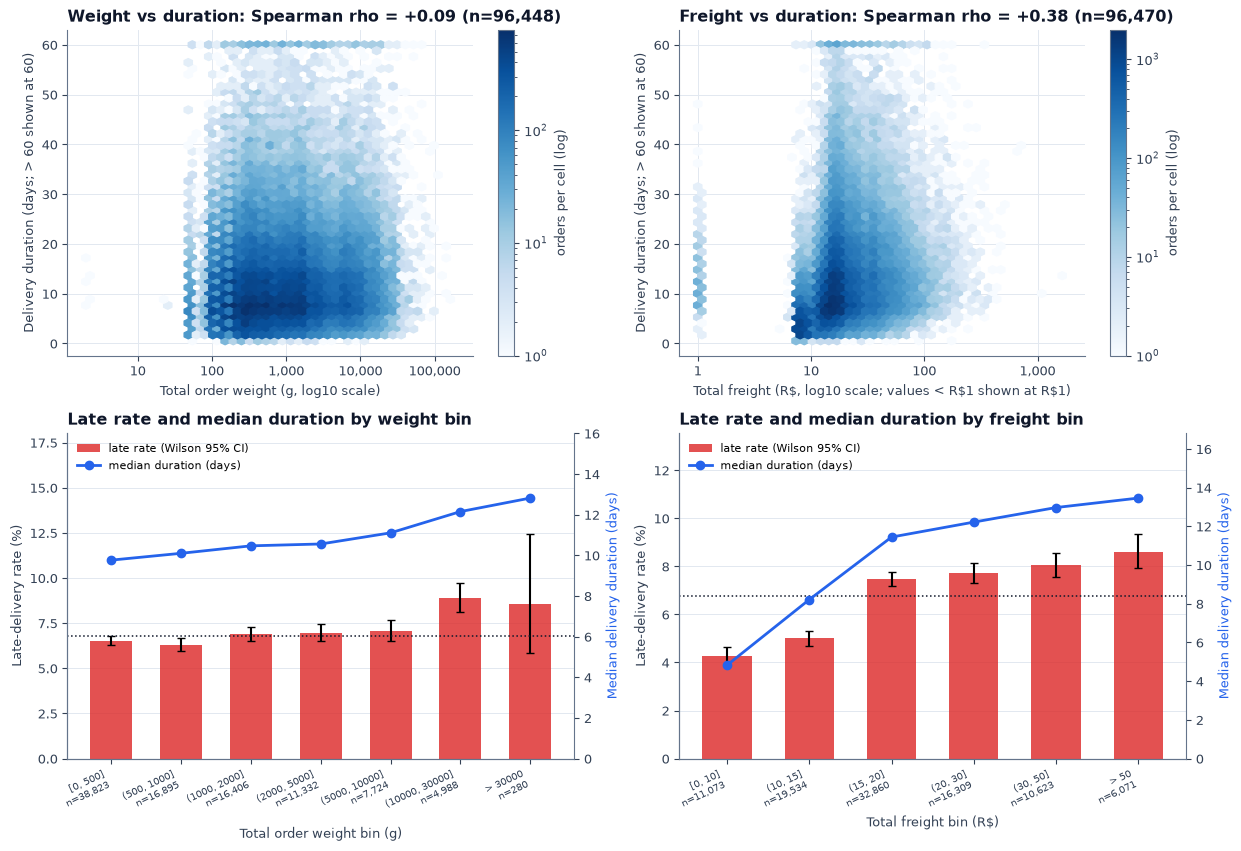

In [24]:
# ---- Figure 24: weight / freight vs duration (hexbin) + binned medians, late rate ---------------------------------
wb = an.weight_bins(d, min_orders=MIN_N)
fb = an.freight_bins(d, min_orders=MIN_N)
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.6))
ax = axes[0, 0]
m_ = d["total_weight_g"].notna() & (d["total_weight_g"] > 0)
hb = ax.hexbin(np.log10(d.loc[m_, "total_weight_g"]), np.clip(d.loc[m_, "delivery_duration_days"], 0, 60), gridsize=45, bins="log", cmap="Blues", mincnt=1)
ax.set_xlabel("Total order weight (g, log10 scale)"); ax.set_ylabel("Delivery duration (days; > 60 shown at 60)")
ax.set_xticks([1, 2, 3, 4, 5]); ax.set_xticklabels(["10", "100", "1,000", "10,000", "100,000"])
r_w = SPEAR[("total_weight_g", "delivery_duration_days")]["rho"]
ax.set_title(f"Weight vs duration: Spearman rho = {r_w:+.2f} (n={SPEAR[('total_weight_g', 'delivery_duration_days')]['n']:,})")
fig.colorbar(hb, ax=ax, label="orders per cell (log)")
ax = axes[0, 1]
hb = ax.hexbin(np.log10(d["total_freight"].clip(lower=1)), np.clip(d["delivery_duration_days"], 0, 60), gridsize=45, bins="log", cmap="Blues", mincnt=1)
ax.set_xlabel("Total freight (R$, log10 scale; values < R$1 shown at R$1)"); ax.set_ylabel("Delivery duration (days; > 60 shown at 60)")
ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["1", "10", "100", "1,000"])
r_f = SPEAR[("total_freight", "delivery_duration_days")]["rho"]
ax.set_title(f"Freight vs duration: Spearman rho = {r_f:+.2f} (n={SPEAR[('total_freight', 'delivery_duration_days')]['n']:,})")
fig.colorbar(hb, ax=ax, label="orders per cell (log)")

def binned_panel(ax, tab, xlabel, title):
    tt = tab.reset_index(drop=True)
    x = np.arange(len(tt))
    ax.bar(x, 100 * tt.late_rate, color=P["red"], alpha=0.8, width=0.6,
           yerr=[100 * (tt.late_rate - tt.late_ci_low), 100 * (tt.late_ci_high - tt.late_rate)], capsize=3, label="late rate (Wilson 95% CI)")
    ax.axhline(BASE * 100, color=P["navy"], ls=":", lw=1.1)
    ax.set_xticks(x); ax.set_xticklabels([f"{b}\nn={int(n):,}" for b, n in zip(tt.bin, tt.n_orders)], fontsize=7, rotation=25, ha="right")
    ax.set_xlabel(xlabel); ax.set_ylabel("Late-delivery rate (%)"); ax.set_title(title); ax.grid(axis="x", visible=False); ax.set_ylim(0, 100 * tt.late_ci_high.max() * 1.45)
    a2 = ax.twinx(); a2.plot(x, tt.median_duration, "o-", color=P["blue"], lw=2, label="median duration (days)")
    a2.set_ylim(0, tt.median_duration.max() * 1.25); a2.set_ylabel("Median delivery duration (days)", color=P["blue"]); a2.grid(False); a2.spines["right"].set_visible(True)
    h1, l1_ = ax.get_legend_handles_labels(); h2, l2_ = a2.get_legend_handles_labels(); ax.legend(h1 + h2, l1_ + l2_, loc="upper left", fontsize=8)
binned_panel(axes[1, 0], wb, "Total order weight bin (g)", "Late rate and median duration by weight bin")
binned_panel(axes[1, 1], fb, "Total freight bin (R$)", "Late rate and median duration by freight bin")
save_show(fig, "24_weight_freight_vs_duration")

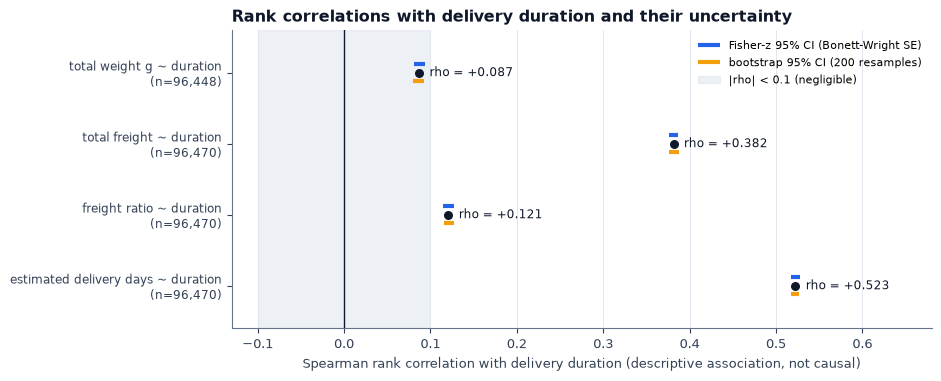

In [25]:
# ---- Figure 25: Spearman rho with Fisher-z and bootstrap confidence intervals --------------------------------------
cont = [(k, v) for k, v in SPEAR.items() if "ci_boot" in v]
fig, ax = plt.subplots(figsize=(9.5, 3.9))
for i, ((x_, y_), r_) in enumerate(cont[::-1]):
    ax.hlines(i + 0.12, *r_["ci_bw"], color=P["blue"], lw=3, label="Fisher-z 95% CI (Bonett-Wright SE)" if i == 0 else None)
    ax.hlines(i - 0.12, *r_["ci_boot"], color=P["amber"], lw=3, label="bootstrap 95% CI (200 resamples)" if i == 0 else None)
    ax.scatter([r_["rho"]], [i], color=P["navy"], zorder=3, s=30)
    ax.text(r_["rho"] + 0.012, i, f"rho = {r_['rho']:+.3f}", ha="left", va="center", fontsize=8.5, color=P["navy"])
ax.set_yticks(range(len(cont))); ax.set_yticklabels([f"{x_.replace('_', ' ')} ~ duration\n(n={r_['n']:,})" for (x_, _), r_ in cont[::-1]], fontsize=8.5)
ax.axvline(0, color=P["navy"], lw=1)
ax.axvspan(-0.1, 0.1, color=P["border"], alpha=0.6, label="|rho| < 0.1 (negligible)")
ax.set_xlim(-0.13, 0.68); ax.set_ylim(-0.6, len(cont) - 0.4)
ax.set_xlabel("Spearman rank correlation with delivery duration (descriptive association, not causal)")
ax.set_title("Rank correlations with delivery duration and their uncertainty"); ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="y", visible=False)
save_show(fig, "25_spearman_confidence_intervals")

### Interpretation of RQ4

* **Weight** is only **negligibly** related to delivery duration: rho = +0.087 (a visible but tiny upward drift in the binned plot). Heavier parcels are not noticeably slower in this data.
* **Freight cost** is **moderately** related to duration: rho = +0.382 (95% CI 0.376 to 0.387). The Fisher-z and bootstrap intervals agree closely and are very narrow, because n is large. Freight is only moderately related to weight (rho = +0.492), and the partial correlation of freight with duration *controlling for weight* is +0.391, essentially unchanged. So the freight-duration link is not a weight effect.
  The data contain no distance, so "freight is a proxy for how far the parcel travels" is a plausible reading, not a tested one. The pattern is consistent with it: inside same-state orders freight and duration are more correlated (rho = +0.277) than inside cross-state orders (rho = +0.124), i.e. part of the pooled association comes from mixing short and long routes.
* **Freight ratio** (freight as a share of item price) has a weak association with duration (rho = +0.121), and **no detectable** association with being late (rank correlation about zero, p = 0.19).
* The **promised** delivery time tracks actual duration strongly (rho = +0.523): Olist's estimate encodes the expected route length. Yet the promise is *slightly negatively* related to lateness (rho = -0.023, negligible), which would be consistent with a longer promise leaving more slack.
* With the binary outcome, all four rank correlations with `is_late` are negligible (largest |rho| = 0.052); where they are statistically significant, that is a matter of n, not of strength.
  **But a rank correlation with a rare 0/1 outcome understates a stepwise pattern, and the binned chart shows one:** across the 6 freight bins (Fig. 24, bottom right) the late rate rises steadily from **4.3%** in the cheapest bin (freight [0, 10], n = 11,073) to **8.6%** in the dearest (freight > 50, n = 6,071), against 6.77% overall, while the median duration climbs from 4.8 to 13.5 days over the same bins (rho of freight with `is_late` = +0.052). This is descriptive and confounded: freight is probably a proxy for distance, and region and period move with it (see RQ1 and RQ5); it is not an effect of freight itself and it does not mean that cheaper shipping prevents lateness.

**Meaning.** Weight and freight describe how long a delivery takes far better than whether it is late, although orders in the highest freight bin are late about 2.0 times as often as those in the lowest (a descriptive, confounded pattern). Duration is mostly geography; lateness is the *excess over the promise*, and the promise already absorbs most of the geography. These are descriptive associations: they do not say that raising or lowering freight changes delivery time.

## 6. RQ5 — Seasonality and other time patterns

**H0:** the late probability is the same in every month (and every weekday). **H1:** it differs.

The data cover only 2016-09 to 2018-08 and the monthly volume grows strongly over the period (see the order-count bars in the monthly chart), so two traps have to be avoided: (i) tiny early months are excluded by the n >= 100 rule (the two single-order months 2016-09 and 2016-12 drop out; 2016-10, with n = 265, is kept, and 2016-11 has no orders at all, so the monthly chart shows gaps there), and (ii) "month of year" pools *different years*, mixing seasonality with year and with one-off events.
We therefore report the monthly series with intervals first, look at the month x year heatmap, and only then run the chi-square tests. Spike months are defined from the series (Wilson interval entirely above 1.5 times the overall late rate); this is a **post-hoc, descriptive** definition, so the comparison with other months carries no confirmatory p-value.

In [26]:
mp = an.monthly_performance(d, min_orders=MIN_N)
rel_m = mp[mp["reliable"]].reset_index(drop=True)
print(f"{len(mp)} purchase months in the data; {len(rel_m)} have n >= {MIN_N} ({', '.join(mp.loc[~mp.reliable, 'purchase_year_month'])} excluded as tiny samples).")
view = rel_m[["purchase_year_month", "n_orders", "n_late", "late_rate", "late_ci_low", "late_ci_high", "mean_duration"]].copy()
for c in ["late_rate", "late_ci_low", "late_ci_high"]:
    view[c] = (100 * view[c]).round(2)
view.rename(columns={"late_rate": "late_%", "late_ci_low": "CI_low_%", "late_ci_high": "CI_high_%"})

23 purchase months in the data; 21 have n >= 100 (2016-09, 2016-12 excluded as tiny samples).


,purchase_year_month,n_orders,n_late,late_%,CI_low_%,CI_high_%,mean_duration
0,2016-10,265,2,0.7500,0.2100,2.7100,19.6006
1,2017-01,750,22,2.9300,1.9400,4.4000,12.6470
2,2017-02,1653,49,2.9600,2.2500,3.9000,13.1688
3,2017-03,2546,116,4.5600,3.8100,5.4400,12.9512
4,2017-04,2303,151,6.5600,5.6200,7.6400,14.9179
5,2017-05,3545,106,2.9900,2.4800,3.6000,11.3224
6,2017-06,3135,95,3.0300,2.4900,3.6900,12.0116
7,2017-07,3872,108,2.7900,2.3200,3.3600,11.5927
8,2017-08,4193,122,2.9100,2.4400,3.4600,11.1471
9,2017-09,4150,182,4.3900,3.8000,5.0500,11.8510


Months whose Wilson interval lies entirely at or above 1.5x the overall rate (10.16%): ['2017-11', '2018-02', '2018-03']
Spike months: 3,158/20,846 late = 15.15%   other months from 2017-01: 3,373/75,357 = 4.48%   difference +10.7 pp (Newcombe 95% CI +10.2 to +11.2), p < 1e-300
Spike months hold 21.6% of all orders but 48.3% of all late orders.


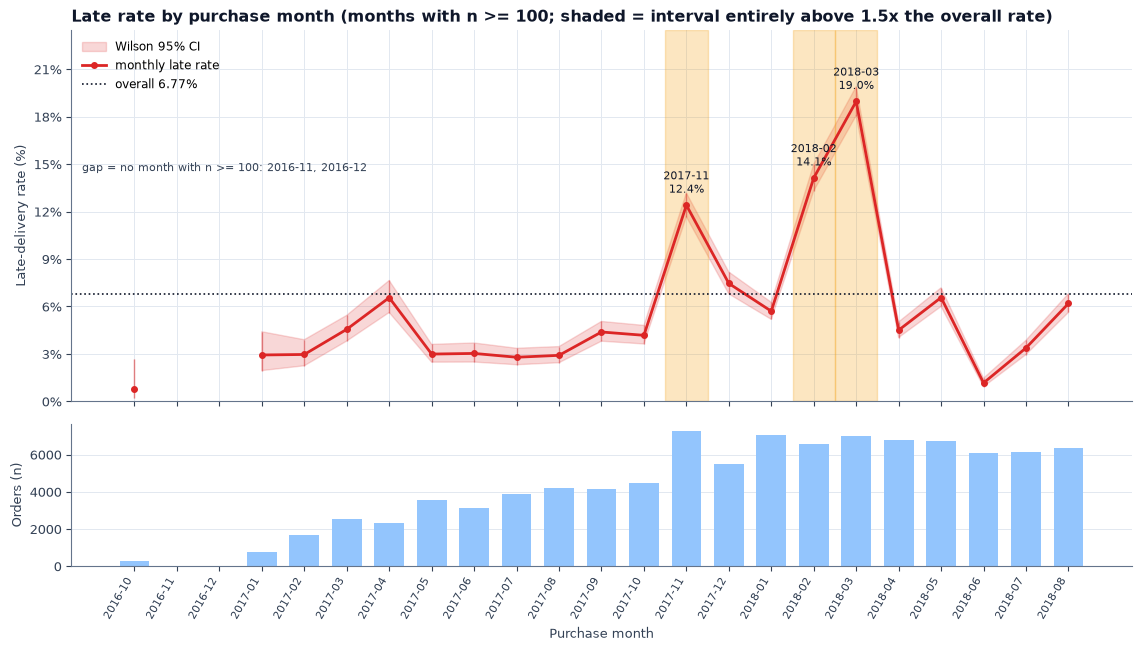

In [27]:
# ---- spike months: identified from the monthly CI screen (interval excludes the overall rate AND rate far above) --
mon = rel_m.copy()
mon["above"] = mon.late_ci_low > BASE
SPIKE_FACTOR = 1.5
spike_df = mon[mon.late_ci_low >= SPIKE_FACTOR * BASE]           # whole Wilson interval at least 1.5x the overall rate
SPIKES = spike_df["purchase_year_month"].tolist()
print(f"Months whose Wilson interval lies entirely at or above {SPIKE_FACTOR}x the overall rate ({pct(SPIKE_FACTOR * BASE)}):", SPIKES)
spike_mask = d.ym.isin(SPIKES)
base_win = d[(d.ym >= "2017-01") & ~spike_mask]
ks, ns_ = int(d.loc[spike_mask, "late"].sum()), int(spike_mask.sum())
ko, no = int(base_win["late"].sum()), len(base_win)
SPK = sa.proportion_diff_ci(ks, ns_, ko, no); SPKZ = sa.two_proportion_ztest(ks, ns_, ko, no)
print(f"Spike months: {ks:,}/{ns_:,} late = {pct(ks / ns_)}   other months from 2017-01: {ko:,}/{no:,} = {pct(ko / no)}   "
      f"difference {100 * SPK['diff']:+.1f} pp (Newcombe 95% CI {100 * SPK['ci_low']:+.1f} to {100 * SPK['ci_high']:+.1f}), p {fmt_p(SPKZ['p_value'])}")
print(f"Spike months hold {ns_ / N:.1%} of all orders but {ks / K_LATE:.1%} of all late orders.")

# ---- Figure 26: monthly late rate with Wilson CI and order volume --------------------------------------------------
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11.5, 6.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.15]})
# calendar axis: months that are absent or below the n threshold stay as gaps (NaN), so the line is not drawn across them
cal = pd.period_range(rel_m.purchase_year_month.iloc[0], rel_m.purchase_year_month.iloc[-1], freq="M").astype(str)
rm = rel_m.set_index("purchase_year_month").reindex(cal)
xm = np.arange(len(cal))
gap_months = [m_ for m_ in cal if m_ not in set(rel_m.purchase_year_month)]
ax.fill_between(xm, 100 * rm.late_ci_low, 100 * rm.late_ci_high, color=P["red"], alpha=0.18, label="Wilson 95% CI")
ax.vlines(xm, 100 * rm.late_ci_low, 100 * rm.late_ci_high, color=P["red"], alpha=0.45, lw=1)   # also shows isolated months
ax.plot(xm, 100 * rm.late_rate, "o-", color=P["red"], lw=2, ms=4, label="monthly late rate")
ax.axhline(BASE * 100, color=P["navy"], ls=":", lw=1.2, label=f"overall {pct(BASE)}")
for i, m_ in enumerate(cal):
    if m_ in SPIKES:
        ax.axvspan(i - 0.5, i + 0.5, color=P["amber"], alpha=0.25)
        ax.annotate(f"{m_}\n{100 * rm.late_rate.iloc[i]:.1f}%", (i, 100 * rm.late_rate.iloc[i]), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8, color=P["navy"])
ax.set_ylabel("Late-delivery rate (%)"); ax.set_title("Late rate by purchase month (months with n >= %d; shaded = interval entirely above 1.5x the overall rate)" % MIN_N)
pct_axis(ax, "y"); ax.set_ylim(0, 100 * rel_m.late_ci_high.max() * 1.18); ax.legend(loc="upper left", fontsize=8.5)
if gap_months:
    ax.text(0.01, 0.62, "gap = no month with n >= %d: %s" % (MIN_N, ", ".join(gap_months)), transform=ax.transAxes, fontsize=8, color=P["slate"])
ax2.bar(xm, rm.n_orders.fillna(0), color=P["blue_light"], width=0.7)
ax2.set_ylabel("Orders (n)"); ax2.set_xlabel("Purchase month"); ax2.set_xticks(xm); ax2.set_xticklabels(cal, rotation=60, ha="right", fontsize=8)
ax2.grid(axis="x", visible=False)
save_show(fig, "26_monthly_late_rate")

In [28]:
# ---- chi-square for time: month-of-year (pooled over years; src) vs a proper year-month test ---------------------
s_m = CHI["purchase_month"]
print(f"Month of year (pooled across years): chi2 = {s_m['chi2']:.1f}, dof = {s_m['dof']}, p = {fmt_p(s_m['p_value'])}, V = {s_m['cramers_v']:.3f} [{s_m['effect_label']}], "
      f"bias-corrected V bootstrap 95% CI {VCI['purchase_month'][0]:.3f} to {VCI['purchase_month'][1]:.3f}")
ym_frame = d[d.ym.isin(rel_m.purchase_year_month)]
ym_chi = sa.chi_square_test(ym_frame, "ym", "late"); ym_man = manual_chi2(ym_frame, "ym", "late")
assert abs(ym_chi["chi2"] - ym_man["chi2"]) < 1e-6
print(f"Year-month ({ym_chi['n_levels_tested']} months with n >= {MIN_N}): chi2 = {ym_chi['chi2']:.1f}, dof = {ym_chi['dof']}, p = {fmt_p(ym_chi['p_value'])}, "
      f"V = {ym_chi['cramers_v']:.3f} [{ym_chi['effect_label']}] (hand-computed chi2 agrees)")
dow = sa.chi_square_test(d, "purchase_dow", "late")
dow_tab = an.binned_stat(d, "purchase_dow", [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5], quantile=False, min_orders=MIN_N)
dow_tab["bin"] = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(dow_tab)]
print(f"Day of week: chi2 = {dow['chi2']:.1f}, dof = {dow['dof']}, p = {fmt_p(dow['p_value'])}, V = {dow['cramers_v']:.3f} [{dow['effect_label']}]")
log_test("RQ5", "chi-square year-month x late", "chi-square", ym_chi["n"], ym_chi["p_value"], "Cramer's V", ym_chi["cramers_v"], ym_chi["effect_label"])
log_test("RQ5", "chi-square purchase_dow x late", "chi-square", dow["n"], dow["p_value"], "Cramer's V", dow["cramers_v"], dow["effect_label"])
display(dow_tab[["bin", "n_orders", "n_late", "late_rate", "late_ci_low", "late_ci_high"]].assign(
    late_rate=lambda t: (100 * t.late_rate).round(2), late_ci_low=lambda t: (100 * t.late_ci_low).round(2),
    late_ci_high=lambda t: (100 * t.late_ci_high).round(2)).rename(columns={"bin": "weekday", "late_rate": "late_%", "late_ci_low": "CI_low_%", "late_ci_high": "CI_high_%"}))

Month of year (pooled across years): chi2 = 2588.0, dof = 11, p = < 1e-300, V = 0.164 [small], bias-corrected V bootstrap 95% CI 0.156 to 0.170
Year-month (21 months with n >= 100): chi2 = 3590.5, dof = 20, p = < 1e-300, V = 0.193 [small] (hand-computed chi2 agrees)
Day of week: chi2 = 26.3, dof = 6, p = 1.99e-04, V = 0.016 [negligible]


,weekday,n_orders,n_late,late_%,CI_low_%,CI_high_%
0,Mon,15701,1168,7.4400,7.0400,7.8600
1,Tue,15502,1093,7.0500,6.6600,7.4600
2,Wed,15074,990,6.5700,6.1800,6.9700
3,Thu,14322,903,6.3000,5.9200,6.7100
4,Fri,13684,960,7.0200,6.6000,7.4600
5,Sat,10555,696,6.5900,6.1400,7.0800
6,Sun,11632,724,6.2200,5.8000,6.6800


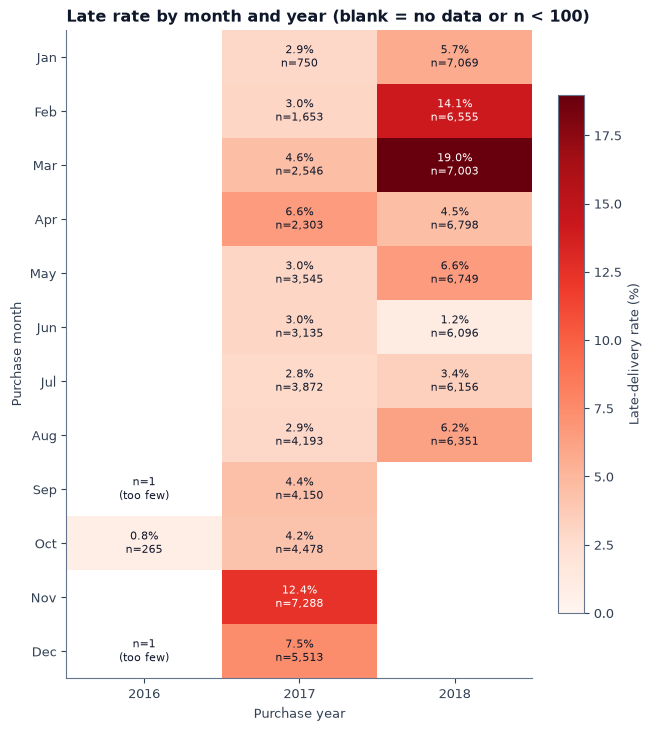

Years with data per calendar month (orders):


,2016,2017,2018
Jan,0,750,7069
Feb,0,1653,6555
Mar,0,2546,7003
Apr,0,2303,6798
May,0,3545,6749
Jun,0,3135,6096
Jul,0,3872,6156
Aug,0,4193,6351
Sep,1,4150,0
Oct,265,4478,0


In [29]:
# ---- Figure 27: month-of-year x year late-rate heatmap (shows why pooling months across years is misleading) ------
hm = d.groupby(["purchase_month", "purchase_year"], observed=True)["late"].agg(["size", "sum"]).reset_index()
hm["rate"] = hm["sum"] / hm["size"]
years = sorted(hm.purchase_year.unique())
rate = np.full((12, len(years)), np.nan); cnt = np.zeros((12, len(years)), dtype=int)
for _, r_ in hm.iterrows():
    rate[int(r_.purchase_month) - 1, years.index(r_.purchase_year)] = r_.rate
    cnt[int(r_.purchase_month) - 1, years.index(r_.purchase_year)] = int(r_["size"])
shown = np.where(cnt >= MIN_N, rate, np.nan)
fig, ax = plt.subplots(figsize=(6.6, 7.4))
im = ax.imshow(100 * shown, cmap="Reds", aspect="auto", vmin=0, vmax=np.nanmax(100 * shown))
ax.set_xticks(range(len(years))); ax.set_xticklabels([str(int(y)) for y in years]); ax.set_yticks(range(12))
ax.set_yticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
for i in range(12):
    for j in range(len(years)):
        if cnt[i, j] == 0:
            continue
        txt = f"{100 * rate[i, j]:.1f}%\nn={cnt[i, j]:,}" if cnt[i, j] >= MIN_N else f"n={cnt[i, j]}\n(too few)"
        ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                color="white" if np.isfinite(shown[i, j]) and shown[i, j] > 0.6 * np.nanmax(shown) else P["navy"])
ax.set_xlabel("Purchase year"); ax.set_ylabel("Purchase month")
ax.set_title("Late rate by month and year (blank = no data or n < %d)" % MIN_N)
ax.grid(False); fig.colorbar(im, ax=ax, label="Late-delivery rate (%)", fraction=0.05)
save_show(fig, "27_month_year_heatmap")
print("Years with data per calendar month (orders):")
pd.DataFrame(cnt, index=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], columns=[int(y) for y in years])

### Interpretation of RQ5

**Result.** Lateness is strongly *time-varying*, but this is better described as **episodes** than as seasonality.
* From 2017-01 to 2018-08 the monthly late rate ranges from **2018-06 (1.2%, n = 6,096)** to **2018-03 (19.0%, n = 7,003)**. Three months stand out, with intervals entirely above 1.5 times the overall rate: **2017-11, 2018-02, 2018-03**. Together they hold 21.6% of all orders but **48.3%** of all late orders (late rate 15.1%, n = 20,846, versus 4.5%, n = 75,357, in the other months from 2017-01).
  The data contain no information on *why* these months are different (demand peaks, carrier capacity, weather, or a change in how the delivery estimate was set), so no explanation can be tested here.
* The chi-square test on **month of the year** is significant with V = 0.164 (**small**), and on **year-month** V = 0.193 (**small**). The month-of-year result must not be read as "March is a bad month": the heatmap shows that March appears twice, in 2017 (**4.6%**) and in 2018 (**19.0%**, the highest of all), and February likewise (3.0% in 2017, 14.1% in 2018). January to August appear in both 2017 and 2018 (October also appears in 2016 and 2017, but 2016 holds only that one month with meaningful volume), and the same calendar month can differ enormously between them; section 8 shows that the pooled month-of-year V falls from 0.164 to 0.070 without the spike months.
  The honest conclusion is **non-stationarity**: rates move between regimes, and a model trained on one period may not transfer to the next.
* **Weekday** differences are statistically detectable but **negligible**: V = 0.016. This is the clearest example in the notebook of significance without practical importance.

**Practical meaning.** Dashboards should show monthly lateness with n and intervals, flag the episodes, and avoid seasonal claims from only two years of data.

## 7. RQ6 — Seller processing time (retrospective)

**H0:** processing time (purchase to carrier hand-over) is unrelated to lateness. **H1:** it is related.

> **RETROSPECTIVE.** The hand-over date is only known after the seller ships, so this analysis explains what happened; it **cannot** be used to predict a delivery at the moment of purchase, and it is deliberately excluded from the model's inputs.

Besides the rate by processing bucket we need to be careful about a **mechanical relationship**: `delivery_duration_days` *contains* processing time (purchase to hand-over, then hand-over to customer), so a positive correlation with duration is partly built in.
Lateness is the better outcome here because it compares the whole journey with a promise fixed at purchase. Orders with a missing or impossible carrier timestamp are left out of this section only.

,days from purchase to carrier hand-over,n_orders,n_late,late_%,CI_low_%,CI_high_%,mean_duration
0,"[0, 1]",18980,621,3.2700,3.0300,3.5300,9.0635
1,"(1, 2]",24010,1185,4.9400,4.6700,5.2200,10.6863
2,"(2, 3]",16299,984,6.0400,5.6800,6.4100,12.0559
3,"(3, 5]",20038,1348,6.7300,6.3900,7.0800,13.5066
4,"(5, 7]",9016,800,8.8700,8.3000,9.4800,15.6670
5,"(7, 14]",6189,898,14.5100,13.6500,15.4100,19.2285
6,> 14,1772,695,39.2200,36.9700,41.5200,30.5983


processing_days available for 96,304 of 96,470 orders (166 missing/invalid carrier timestamps are excluded from this section only).


processing ~ duration : rho = +0.419, Fisher-z CI 0.413 to 0.424, bootstrap CI 0.413 to 0.424  (partly mechanical: processing is a component of duration)
processing ~ is_late  : rho = +0.131, p < 1e-300 [weak], n = 96,304
carrier->customer days ~ is_late: rho = +0.345 [moderate] (the other component of duration, for comparison)
processing ~ carrier->customer days: rho = +0.054 (a slow hand-over does not mechanically make the transit leg longer)
chi-square processing bucket x late: chi2 = 4110.4, dof = 6, p = < 1e-300, V = 0.207 [small], n = 96,304
Mann-Whitney processing days late (n=6,531, median 3.50 d) vs on time (n=89,773, median 2.15 d): p < 1e-300, rank-biserial = +0.302


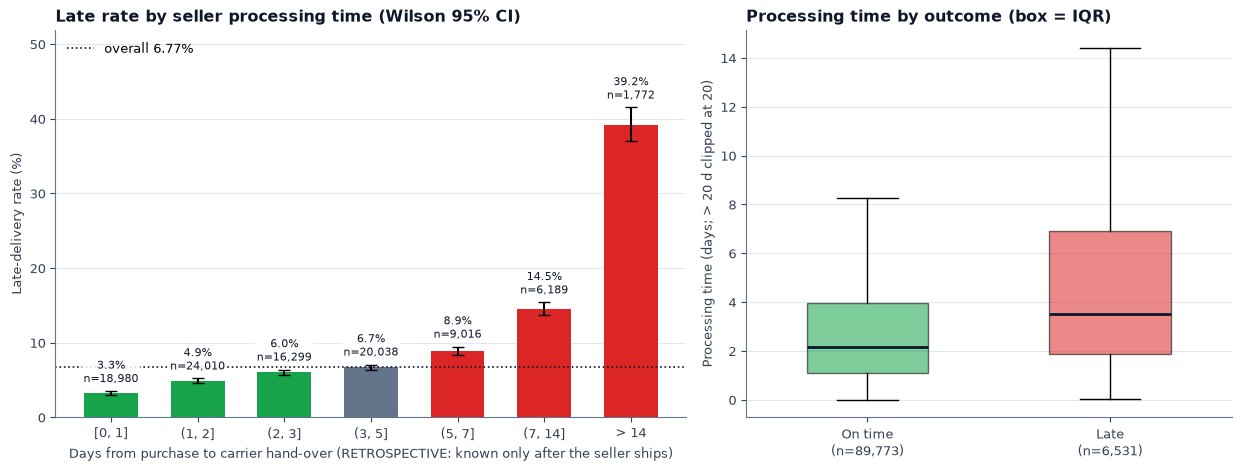

In [30]:
pt = an.late_by_processing_bucket(d, min_orders=MIN_N)
view = pt[["bin", "n_orders", "n_late", "late_rate", "late_ci_low", "late_ci_high", "mean_duration"]].copy()
for c in ["late_rate", "late_ci_low", "late_ci_high"]:
    view[c] = (100 * view[c]).round(2)
display(view.rename(columns={"bin": "days from purchase to carrier hand-over", "late_rate": "late_%", "late_ci_low": "CI_low_%", "late_ci_high": "CI_high_%"}))

n_proc = int(d.processing_days.notna().sum())
print(f"processing_days available for {n_proc:,} of {N:,} orders ({N - n_proc:,} missing/invalid carrier timestamps are excluded from this section only).")
SP_PROC = {}
for y_ in ["delivery_duration_days"]:
    SP_PROC[y_] = spearman_full(d, "processing_days", y_, B=200)
r_pd = SP_PROC["delivery_duration_days"]
srcp = sa.spearman_test(d, "processing_days", "delivery_duration_days")
assert abs(srcp["rho"] - r_pd["rho"]) < 1e-10
sp_late = sa.spearman_test(d, "processing_days", "late")
sp_c2c = sa.spearman_test(d, "carrier_to_customer_days", "late")
sp_pc = sa.spearman_test(d, "processing_days", "carrier_to_customer_days")
print(f"processing ~ duration : rho = {r_pd['rho']:+.3f}, Fisher-z CI {r_pd['ci_bw'][0]:.3f} to {r_pd['ci_bw'][1]:.3f}, bootstrap CI {r_pd['ci_boot'][0]:.3f} to {r_pd['ci_boot'][1]:.3f}  (partly mechanical: processing is a component of duration)")
print(f"processing ~ is_late  : rho = {sp_late['rho']:+.3f}, p {fmt_p(sp_late['p_value'])} [{sp_late['strength_label']}], n = {sp_late['n']:,}")
print(f"carrier->customer days ~ is_late: rho = {sp_c2c['rho']:+.3f} [{sp_c2c['strength_label']}] (the other component of duration, for comparison)")
print(f"processing ~ carrier->customer days: rho = {sp_pc['rho']:+.3f} (a slow hand-over does not mechanically make the transit leg longer)")

pb = d[d.processing_days.notna()].copy()
pb["bucket"] = pd.cut(pb.processing_days, [-0.001, 1, 2, 3, 5, 7, 14, np.inf], labels=pt["bin"].tolist())
chi_pb = sa.chi_square_test(pb, "bucket", "late")
x_late = pb.loc[pb.late == 1, "processing_days"]; x_ok = pb.loc[pb.late == 0, "processing_days"]
mw_p = stats.mannwhitneyu(x_late, x_ok, alternative="two-sided")
rb_p = 2 * mw_p.statistic / (len(x_late) * len(x_ok)) - 1
print(f"chi-square processing bucket x late: chi2 = {chi_pb['chi2']:.1f}, dof = {chi_pb['dof']}, p = {fmt_p(chi_pb['p_value'])}, V = {chi_pb['cramers_v']:.3f} [{chi_pb['effect_label']}], n = {chi_pb['n']:,}")
print(f"Mann-Whitney processing days late (n={len(x_late):,}, median {x_late.median():.2f} d) vs on time (n={len(x_ok):,}, median {x_ok.median():.2f} d): "
      f"p {fmt_p(max(mw_p.pvalue, P_FLOOR))}, rank-biserial = {rb_p:+.3f}")
log_test("RQ6", "Spearman processing_days ~ is_late (retrospective)", "spearman", sp_late["n"], sp_late["p_value"], "Spearman rho", sp_late["rho"], sp_late["strength_label"])
log_test("RQ6", "Spearman processing_days ~ duration (retrospective)", "spearman", r_pd["n"], r_pd["p"], "Spearman rho", r_pd["rho"], strength(r_pd["rho"]))
log_test("RQ6", "chi-square processing bucket x late (retrospective)", "chi-square", chi_pb["n"], chi_pb["p_value"], "Cramer's V", chi_pb["cramers_v"], chi_pb["effect_label"])
log_test("RQ6", "Mann-Whitney processing_days by late (retrospective)", "mann-whitney", len(x_late) + len(x_ok), max(mw_p.pvalue, P_FLOOR), "rank-biserial", rb_p, sa._rank_biserial_label(rb_p))

# ---- Figure 28 ----
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(pt))
colr = [P["red"] if lo_ > BASE else P["green"] if hi_ < BASE else P["slate_light"] for lo_, hi_ in zip(pt.late_ci_low, pt.late_ci_high)]
ax.bar(x, 100 * pt.late_rate, color=colr, width=0.62,
       yerr=[100 * (pt.late_rate - pt.late_ci_low), 100 * (pt.late_ci_high - pt.late_rate)], capsize=4)
for xi, (r_, n_) in enumerate(zip(pt.late_rate, pt.n_orders)):
    ax.text(xi, 100 * pt.late_ci_high.iloc[xi] + 1.2, f"{100 * r_:.1f}%\nn={int(n_):,}", ha="center", fontsize=8, color=P["navy"],
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.axhline(BASE * 100, color=P["navy"], ls=":", lw=1.2, label=f"overall {pct(BASE)}")
ax.set_xticks(x); ax.set_xticklabels(pt["bin"]); ax.set_ylim(0, 100 * pt.late_ci_high.max() * 1.25)
ax.set_xlabel("Days from purchase to carrier hand-over (RETROSPECTIVE: known only after the seller ships)")
ax.set_ylabel("Late-delivery rate (%)"); ax.set_title("Late rate by seller processing time (Wilson 95% CI)"); ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
bp = ax2.boxplot([x_ok.clip(upper=20), x_late.clip(upper=20)], tick_labels=[f"On time\n(n={len(x_ok):,})", f"Late\n(n={len(x_late):,})"], showfliers=False,
                 patch_artist=True, widths=0.5, medianprops={"color": P["navy"], "lw": 2})
for patch, c in zip(bp["boxes"], [P["green"], P["red"]]):
    patch.set_facecolor(c); patch.set_alpha(0.55)
ax2.set_ylabel("Processing time (days; > 20 d clipped at 20)"); ax2.set_title("Processing time by outcome (box = IQR)"); ax2.grid(axis="x", visible=False)
save_show(fig, "28_processing_time_vs_lateness")

### Interpretation of RQ6

* Late rates climb steadily with processing time: **3.3%** for orders handed over within a day (n = 18,980) up to **39.2%** when hand-over took more than 14 days (n = 1,772).
* Late orders had a median processing time of 3.50 days versus 2.15 days for on-time orders (Mann-Whitney, rank-biserial r = 0.30, at the small/medium boundary). The rank correlation with lateness is **weak** (rho = +0.131), because most orders have short processing times and the relationship is concentrated in the long tail.
* Processing time with delivery duration: rho = +0.419 (moderate), as expected given the mechanical overlap. For comparison, the *transit* leg (carrier to customer) has the stronger rank correlation with lateness (rho = +0.345), and processing time is almost unrelated to transit time (rho = +0.054): a slow hand-over does not slow down the transit, but both add up to a late arrival.

**Meaning.** Slow seller processing is **associated with** a higher late rate, most visibly beyond a week. Whether a lower processing time would reduce lateness cannot be answered from this data (sellers who are slow to ship may also differ in region, product or load). Because it is retrospective, processing time is useful for diagnosing seller performance after the fact, not for predicting at checkout.

## 8. Robustness: sensitivity to the spike months, and why n matters

Two checks that guard against over-reading the p-values.

**(a) Sensitivity.** Repeat the chi-square battery without the spike months from section 6 (n = 75,624 orders, overall late rate 4.46%). An association that is mostly produced by those episodes should shrink sharply.
**(b) Effect size versus sample size.** Draw random subsamples of the data and test same-state x late each time. If significance is mostly a matter of n, the *share of subsamples reaching p < 0.05* should rise with n while the *effect size* stays put.

The sensitivity result: Cramer's V for the customer state falls from 0.136 to 0.106, for same-state from 0.068 to 0.027, and for the month of the year from 0.164 to 0.070;
the category effect is unchanged (0.039 to 0.040). So regional, same-state and seasonal patterns depend partly on the spike episodes, whereas the (small) category pattern does not.

In [31]:
# ---- (a) Sensitivity: repeat the chi-square battery without the spike months ---------------------------------------
d_ns = d[~d.ym.isin(SPIKES)]
rows = []
for col in ["customer_state", "product_category", "same_state", "purchase_month", "purchase_dow"]:
    known = (lambda f: f[f["product_category"] != UNKNOWN_CAT]) if col == "product_category" else (lambda f: f)   # RQ2 excludes 'unknown'
    full = sa.chi_square_test(known(d), col, "late"); ns_r = sa.chi_square_test(known(d_ns), col, "late")
    rows.append({"variable": col, "V (all orders)": full["cramers_v"], "V (without spike months)": ns_r["cramers_v"],
                 "change": ns_r["cramers_v"] / full["cramers_v"] - 1, "p (without spike months)": fmt_p(ns_r["p_value"]),
                 "label (without)": ns_r["effect_label"], "n (without)": ns_r["n"]})
SENS = pd.DataFrame(rows)
SENS["change"] = SENS["change"].map(lambda v: f"{v:+.0%}")
print(f"Without {', '.join(SPIKES)}: n = {len(d_ns):,}, overall late rate = {pct(d_ns.late.mean())} (vs {pct(BASE)} with them).")
SENS

Without 2017-11, 2018-02, 2018-03: n = 75,624, overall late rate = 4.46% (vs 6.77% with them).


,variable,V (all orders),V (without spike months),change,p (without spike months),label (without),n (without)
0,customer_state,0.1359,0.1059,-22%,1.18e-163,small,75624
1,product_category,0.0390,0.0397,+2%,9.48e-08,negligible,74601
2,same_state,0.0676,0.0269,-60%,1.36e-13,negligible,75624
3,purchase_month,0.1638,0.0697,-57%,6.68e-73,negligible,75624
4,purchase_dow,0.0165,0.0251,+52%,1.38e-08,negligible,75624


In [32]:
# ---- (b) Significance depends on n, effect size does not: random subsamples of the data -------------------------------
rng = np.random.default_rng(SEED)
sizes = [200, 500, 1000, 2000, 5000, 20000, N]
REP = 300
rows = []
for n_s in sizes:
    ps, vs = [], []
    reps = 1 if n_s == N else REP
    for _ in range(reps):
        idx = rng.choice(N, n_s, replace=False) if n_s < N else np.arange(N)
        sub = d.iloc[idx]
        t_ = pd.crosstab(sub.same_state, sub.late).reindex(index=[0, 1], columns=[0, 1], fill_value=0).to_numpy()
        if t_.sum(axis=0).min() == 0 or t_.sum(axis=1).min() == 0:
            continue
        c2, p_, _, _ = stats.chi2_contingency(t_, correction=False)
        ps.append(p_); vs.append(math.sqrt(c2 / t_.sum()))
    ps, vs = np.array(ps), np.array(vs)
    rows.append({"subsample n": n_s, "repetitions": len(ps), "median Cramer V": np.median(vs),
                 "median p-value": np.median(ps), "share of draws with p < 0.05": float((ps < ALPHA).mean())})
SUBS = pd.DataFrame(rows)
display(SUBS.assign(**{"median p-value": SUBS["median p-value"].map(fmt_p), "share of draws with p < 0.05": SUBS["share of draws with p < 0.05"].map(lambda v: f"{v:.0%}")}))

,subsample n,repetitions,median Cramer V,median p-value,share of draws with p < 0.05
0,200,300,0.0712,0.3138,13%
1,500,300,0.0669,0.1344,29%
2,1000,300,0.0680,0.0315,56%
3,2000,300,0.0654,0.0034,84%
4,5000,300,0.0677,1.69e-06,100%
5,20000,300,0.0676,1.26e-21,100%
6,96470,1,0.0676,5.14e-98,100%


## 9. Cross-checks, multiple testing and summary

**Cross-check.** All chi-square, Spearman and Kruskal-Wallis results in the project's `run_all_tests` battery are recomputed directly with scipy; the maximum absolute difference is printed.

**Multiple testing.** The notebook runs a family of related hypothesis tests, listed below; each is Holm-adjusted for the number run. With a few exceptions the p-values are so small that adjustment changes no verdict, which is a statement about the sample size,
not about the importance of the effects. The more informative columns are the **effect sizes**, drawn in the figure that follows. (The 24 state-vs-rest and 51 category-vs-rest comparisons in sections 2-3 were adjusted separately within their own families, where adjustment *did* matter.)

In [33]:
# ---- (c) Cross-check: every test in the src battery against a direct scipy computation -----------------------------
battery = sa.run_all_tests(d)
summ = battery["summary"]
chk = []
for key, r in battery["spearman"].items():
    x_, y_ = key.split("~")
    f = d[[x_, y_]].astype(float).dropna()
    rho_s, p_s = stats.spearmanr(f[x_], f[y_])
    chk.append({"test": f"spearman {key}", "src": r["rho"], "scipy": float(rho_s), "|diff|": abs(r["rho"] - rho_s)})
for col, r in battery["chi_square"].items():
    ref = MAN[col] if col != "product_category" else manual_chi2(d, col)      # the battery runs on ALL orders (incl. 'unknown'), so does its reference
    chk.append({"test": f"chi-square {col}", "src": r["chi2"], "scipy": ref["chi2"], "|diff|": abs(r["chi2"] - ref["chi2"])})
gc = battery["group_comparison"]["delivery_duration_days~customer_state"]
big_states = d["customer_state"].value_counts()
big_states = big_states[big_states >= 30].index
H, pH = stats.kruskal(*[g["delivery_duration_days"].to_numpy() for _, g in d[d.customer_state.isin(big_states)].groupby("customer_state", observed=True)])
chk.append({"test": "kruskal duration by customer_state", "src": gc["statistic"], "scipy": float(H), "|diff|": abs(gc["statistic"] - H)})
chk = pd.DataFrame(chk)
display(chk)
assert chk["|diff|"].max() < 1e-6
print(f"Maximum absolute difference between src and direct scipy over {len(chk)} statistics: {chk['|diff|'].max():.2e}")
log_test("RQ1", "Kruskal-Wallis duration by customer_state", "kruskal", gc["n"], gc["p_value"], "epsilon-squared", gc["effect_size"], gc["effect_label"])

,test,src,scipy,|diff|
0,spearman total_weight_g~delivery_duration_days,0.0870,0.0870,0.0000
1,spearman total_freight~delivery_duration_days,0.3815,0.3815,0.0000
2,spearman total_weight_g~total_freight,0.4921,0.4921,0.0000
3,spearman freight_ratio~is_late,0.0042,0.0042,0.0000
4,spearman total_weight_g~is_late,0.0165,0.0165,0.0000
5,spearman estimated_delivery_days~is_late,-0.0225,-0.0225,0.0000
6,chi-square customer_state,"1,782.3759","1,782.3759",0.0000
7,chi-square product_category,144.8374,144.8374,0.0000
8,chi-square same_state,441.4880,441.4880,0.0000
9,chi-square purchase_month,"2,588.0054","2,588.0054",0.0000


Maximum absolute difference between src and direct scipy over 11 statistics: 0.00e+00


In [34]:
# ---- Holm adjustment over the whole notebook-wide family of tests --------------------------------------------------
led = pd.DataFrame(LEDGER)
led["p_holm"] = sa.holm_adjust(led["p_value"].to_numpy())
led["significant_raw"] = led["p_value"] < ALPHA
led["significant_holm"] = led["p_holm"] < ALPHA
m_tests = len(led)
shown = led.assign(p_value=led.p_value.map(fmt_p), p_holm=led.p_holm.map(fmt_p))[
    ["rq", "test", "n", "p_value", "p_holm", "significant_holm", "effect_name", "effect", "effect_label"]]
print(f"{m_tests} hypothesis tests were run in this notebook's primary family; Holm-adjusted at alpha = {ALPHA}:")
print(f"  significant before adjustment: {int(led.significant_raw.sum())}   after Holm: {int(led.significant_holm.sum())}")
shown

21 hypothesis tests were run in this notebook's primary family; Holm-adjusted at alpha = 0.05:
  significant before adjustment: 20   after Holm: 20


,rq,test,n,p_value,p_holm,significant_holm,effect_name,effect,effect_label
0,RQ1,chi-square customer_state x late,96470,< 1e-300,4.67e-307,True,Cramer's V,0.1359,small
1,RQ2,chi-square product_category x late,95112,3.27e-10,1.64e-09,True,Cramer's V,0.0390,negligible
2,RQ3,chi-square same_state x late,96470,5.14e-98,4.11e-97,True,Cramer's V,0.0676,negligible
3,RQ5,chi-square purchase_month x late,96470,< 1e-300,4.67e-307,True,Cramer's V,0.1638,small
4,RQ3,Mann-Whitney duration by same_state,96470,< 1e-300,4.67e-307,True,rank-biserial,0.5956,large
5,RQ3,chi-square-2x2 / Mantel-Haenszel same_state x ...,93241,7.09e-05,2.13e-04,True,MH odds ratio,0.8265,adjusted for state
6,RQ4,Spearman total_weight_g ~ delivery_duration_days,96448,2.68e-161,2.42e-160,True,Spearman rho,0.0870,negligible
7,RQ4,Spearman total_freight ~ delivery_duration_days,96470,< 1e-300,4.67e-307,True,Spearman rho,0.3815,moderate
8,RQ4,Spearman freight_ratio ~ delivery_duration_days,96470,< 1e-300,4.67e-307,True,Spearman rho,0.1209,weak
9,RQ4,Spearman estimated_delivery_days ~ delivery_du...,96470,< 1e-300,4.67e-307,True,Spearman rho,0.5225,strong


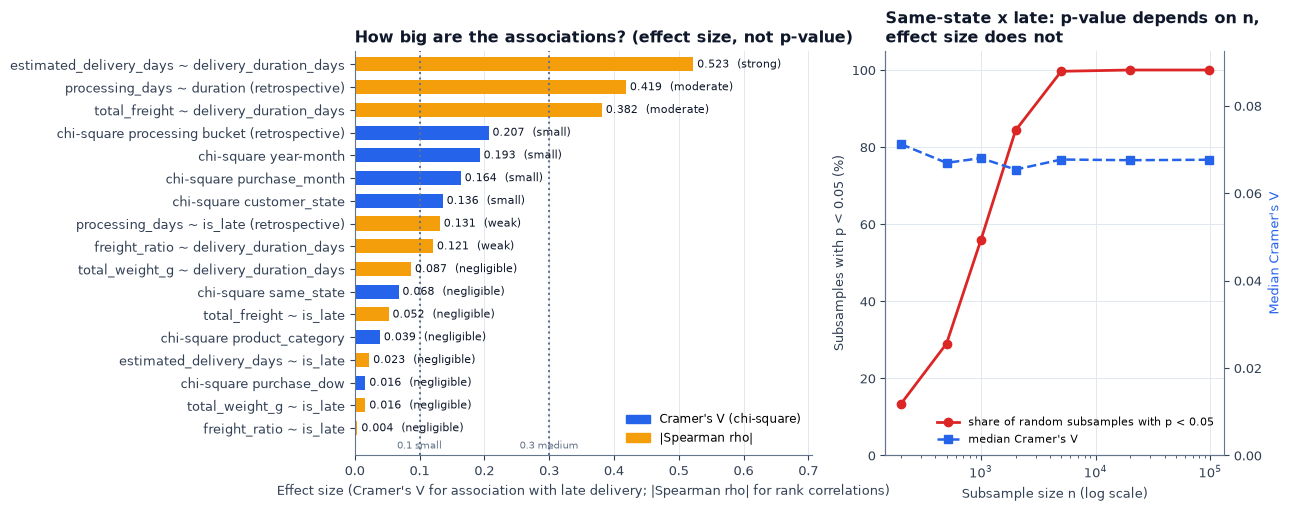

In [35]:
# ---- Figure 29: effect sizes at a glance + p-value vs sample size ---------------------------------------------------
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
bars = [("Cramer's V", r["test"].replace(" x late", ""), r["effect"], r["effect_label"]) for _, r in led.iterrows() if r["effect_name"] == "Cramer's V"]
sp_rows = [("|Spearman rho|", r["test"].replace("Spearman ", ""), abs(r["effect"]), r["effect_label"]) for _, r in led.iterrows() if r["effect_name"] == "Spearman rho"]
allb = pd.DataFrame(bars + sp_rows, columns=["kind", "label", "value", "verdict"]).sort_values("value").reset_index(drop=True)
ax.barh(allb.label, allb.value, color=[P["blue"] if k == "Cramer's V" else P["amber"] for k in allb.kind], height=0.62)
for i, (v, vd) in enumerate(zip(allb.value, allb.verdict)):
    ax.text(v + 0.006, i, f"{v:.3f}  ({vd})", va="center", fontsize=8, color=P["navy"])
ax.axvline(0.1, color=P["slate_light"], ls=":"); ax.axvline(0.3, color=P["slate_light"], ls=":")
ax.text(0.1, -0.9, "0.1 small", fontsize=7.5, color=P["slate_light"], ha="center"); ax.text(0.3, -0.9, "0.3 medium", fontsize=7.5, color=P["slate_light"], ha="center")
ax.set_xlim(0, max(allb.value) * 1.35); ax.set_ylim(-1.2, len(allb) - 0.4)
ax.set_xlabel("Effect size (Cramer's V for association with late delivery; |Spearman rho| for rank correlations)")
ax.set_title("How big are the associations? (effect size, not p-value)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=P["blue"], label="Cramer's V (chi-square)"), Patch(color=P["amber"], label="|Spearman rho|")], loc="lower right", fontsize=8.5)

ax2.plot(SUBS["subsample n"], SUBS["share of draws with p < 0.05"] * 100, "o-", color=P["red"], lw=2, label="share of random subsamples with p < 0.05")
ax2.set_xscale("log"); ax2.set_ylim(0, 105); ax2.set_xlabel("Subsample size n (log scale)"); ax2.set_ylabel("Subsamples with p < 0.05 (%)")
a3 = ax2.twinx(); a3.plot(SUBS["subsample n"], SUBS["median Cramer V"], "s--", color=P["blue"], lw=1.8, label="median Cramer's V")
a3.set_ylabel("Median Cramer's V", color=P["blue"]); a3.set_ylim(0, max(SUBS["median Cramer V"]) * 1.3); a3.grid(False); a3.spines["right"].set_visible(True)
h1, l1_ = ax2.get_legend_handles_labels(); h2, l2_ = a3.get_legend_handles_labels(); ax2.legend(h1 + h2, l1_ + l2_, loc="lower right", fontsize=8)
ax2.set_title("Same-state x late: p-value depends on n,\neffect size does not")
save_show(fig, "29_effect_sizes_and_sample_size")

### What the cross-checks and the effect-size figure show

* Wherever the notebook recomputed a statistic with plain scipy (chi-square, Spearman, Kruskal-Wallis, Mann-Whitney, same-state proportion tests), it agrees with the project module to numerical precision; the state-vs-rest, category-vs-rest and spike-month comparisons were not independently recomputed here.
* **20 of 21** tests are significant before adjustment and **20** after Holm adjustment; the exception is **Spearman freight ratio ~ is late** (not significant either way). Nearly everything is "significant" because n is about 96,000 — that cannot distinguish important from unimportant effects.
* The subsample experiment makes the point: with n = 200 only 13% of random subsamples detect the same-state difference, with n = 2,000 84%, with n = 20,000 all of them (share = 100%), while the median Cramer's V stays near 0.068 throughout.
* Judged by **effect size**, the associations with lateness are small at best: customer state, calendar month and processing time reach "small" (V between 0.1 and 0.3); product category, weekday, and the rank correlations of weight, freight, freight ratio and the promise with lateness are negligible. Larger correlations appear only with delivery *duration* (the promise, freight and, mechanically, processing time).

In [36]:
# ---- Findings table: one row per research question, numbers computed from the objects above ------------------------
def top_state_rows():
    s_ = st[st.reliable].sort_values("late_rate", ascending=False)
    return s_.iloc[0], s_.iloc[-1]
hi_s, lo_s = top_state_rows()
findings = pd.DataFrame([
    ("RQ1 Region", "customer_state x late", CHI["customer_state"]["n"], f"V = {CHI['customer_state']['cramers_v']:.3f} ({CHI['customer_state']['effect_label']})",
     f"{hi_s.customer_state} {pct(hi_s.late_rate)} (n={int(hi_s.n_orders):,}) to {lo_s.customer_state} {pct(lo_s.late_rate)} (n={int(lo_s.n_orders):,})",
     f"{int(state_vs_rest.sig_holm.sum())} of {len(state_vs_rest)} states differ from the rest after Holm"),
    ("RQ2 Category", "product_category x late", CHI["product_category"]["n"], f"V = {CHI['product_category']['cramers_v']:.3f} ({CHI['product_category']['effect_label']})",
     f"{len(rel_cat)} categories with n>={MIN_N}: {pct(rel_cat.late_rate.min())} to {pct(rel_cat.late_rate.max())}",
     f"{int(cat_vs_rest.sig_holm.sum())} of {len(cat_vs_rest)} categories differ from the rest after Holm"),
    ("RQ3 Same vs cross state", "same_state x late", n1 + n0, f"V = {CHI['same_state']['cramers_v']:.3f} ({CHI['same_state']['effect_label']}); MH OR = {OR_MH:.2f}",
     f"{pct(p1)} (n={n1:,}) vs {pct(p0)} (n={n0:,}); duration median {np.median(x_same):.1f} vs {np.median(x_cross):.1f} d",
     f"crude OR {OR_crude:.2f} shrinks to {OR_MH:.2f} after adjusting for state"),
    ("RQ4 Weight / freight", "Spearman vs duration", SPEAR[("total_freight", "delivery_duration_days")]["n"],
     f"rho(weight) = {SPEAR[('total_weight_g', 'delivery_duration_days')]['rho']:+.2f}, rho(freight) = {SPEAR[('total_freight', 'delivery_duration_days')]['rho']:+.2f}",
     f"weight {strength(SPEAR[('total_weight_g', 'delivery_duration_days')]['rho'])}; freight {strength(SPEAR[('total_freight', 'delivery_duration_days')]['rho'])}",
     f"freight partial rho given weight = {PART['freight|weight'][0]:+.2f}"),
    ("RQ5 Time", "year-month x late", ym_chi["n"], f"V = {ym_chi['cramers_v']:.3f} ({ym_chi['effect_label']})",
     f"spike months {pct(ks / ns_)} vs other months {pct(ko / no)}", f"{', '.join(SPIKES)} hold {ks / K_LATE:.0%} of late orders"),
    ("RQ6 Processing (retrospective)", "processing_days ~ is_late", sp_late["n"], f"rho = {sp_late['rho']:+.2f} ({sp_late['strength_label']})",
     f"late rate {pct(pt.late_rate.iloc[0])} (<=1 d) to {pct(pt.late_rate.iloc[-1])} (>14 d)", "not available at purchase time"),
], columns=["question", "test", "n", "effect size", "key numbers", "context"])
findings

,question,test,n,effect size,key numbers,context
0,RQ1 Region,customer_state x late,96470,V = 0.136 (small),AL 21.41% (n=397) to AM 2.76% (n=145),16 of 24 states differ from the rest after Holm
1,RQ2 Category,product_category x late,95112,V = 0.039 (negligible),51 categories with n>=100: 2.60% to 11.92%,2 of 51 categories differ from the rest after ...
2,RQ3 Same vs cross state,same_state x late,96470,V = 0.068 (negligible); MH OR = 0.83,"4.50% (n=34,696) vs 8.05% (n=61,774); duration...",crude OR 0.54 shrinks to 0.83 after adjusting ...
3,RQ4 Weight / freight,Spearman vs duration,96470,"rho(weight) = +0.09, rho(freight) = +0.38",weight negligible; freight moderate,freight partial rho given weight = +0.39
4,RQ5 Time,year-month x late,96468,V = 0.193 (small),spike months 15.15% vs other months 4.48%,"2017-11, 2018-02, 2018-03 hold 48% of late orders"
5,RQ6 Processing (retrospective),processing_days ~ is_late,96304,rho = +0.13 (weak),late rate 3.27% (<=1 d) to 39.22% (>14 d),not available at purchase time


In [37]:
# ---- Machine-readable key results (the build script compares these with its own independent computation) ----------
def _f(x): return float(x)
_mm = rel_m[rel_m.purchase_year_month >= "2017-01"]
KEY_RESULTS = {
    "N": int(N), "K_LATE": int(K_LATE), "BASE": _f(BASE), "BASE_CI_LOW": _f(an.wilson_ci(K_LATE, N)[0]), "BASE_CI_HIGH": _f(an.wilson_ci(K_LATE, N)[1]),
    "chi2_state": _f(CHI["customer_state"]["chi2"]), "v_state": _f(CHI["customer_state"]["cramers_v"]), "dof_state": int(CHI["customer_state"]["dof"]),
    "v_state_corr": _f(CHI["customer_state"]["cramers_v_corrected"]), "v_state_lo": _f(VCI["customer_state"][0]), "v_state_hi": _f(VCI["customer_state"][1]),
    "chi2_cat": _f(CHI["product_category"]["chi2"]), "v_cat": _f(CHI["product_category"]["cramers_v"]), "dof_cat": int(CHI["product_category"]["dof"]),
    "v_cat_corr": _f(CHI["product_category"]["cramers_v_corrected"]), "v_cat_lo": _f(VCI["product_category"][0]), "v_cat_hi": _f(VCI["product_category"][1]),
    "chi2_same": _f(CHI["same_state"]["chi2"]), "v_same": _f(CHI["same_state"]["cramers_v"]),
    "chi2_month": _f(CHI["purchase_month"]["chi2"]), "v_month": _f(CHI["purchase_month"]["cramers_v"]),
    "v_ym": _f(ym_chi["cramers_v"]), "v_dow": _f(dow["cramers_v"]),
    "state_hi_name": str(hi_s.customer_state), "state_hi_rate": _f(hi_s.late_rate), "state_hi_n": int(hi_s.n_orders),
    "state_lo_name": str(lo_s.customer_state), "state_lo_rate": _f(lo_s.late_rate), "state_lo_n": int(lo_s.n_orders),
    "n_state_sig_raw": int(state_vs_rest.sig_raw.sum()), "n_state_sig_holm": int(state_vs_rest.sig_holm.sum()), "n_state_tested": int(len(state_vs_rest)),
    "n_cat_sig_raw": int(cat_vs_rest.sig_raw.sum()), "n_cat_sig_holm": int(cat_vs_rest.sig_holm.sum()), "n_cat_tested": int(len(cat_vs_rest)),
    "stab_train_same": _f(STAB.loc["train", "late % same-state"] / 100), "stab_train_cross": _f(STAB.loc["train", "late % cross-state"] / 100),
    "stab_val_same": _f(STAB.loc["validation", "late % same-state"] / 100), "stab_val_cross": _f(STAB.loc["validation", "late % cross-state"] / 100),
    "stab_test_same": _f(STAB.loc["test", "late % same-state"] / 100), "stab_test_cross": _f(STAB.loc["test", "late % cross-state"] / 100),
    "stab_test_gap_lo_pp": _f(STAB.loc["test", "CI low (pp)"]), "stab_test_gap_hi_pp": _f(STAB.loc["test", "CI high (pp)"]),
    "stab_n_months": int(N_MONTHS), "stab_n_months_same_higher": int(N_MONTHS_SAME_HIGHER), "stab_months_same_higher": ",".join(mo.index[mo.gap_pp > 0]),
    "fb_n_bins": int(len(fb)), "fb_first_label": str(fb["bin"].iloc[0]), "fb_last_label": str(fb["bin"].iloc[-1]),
    "fb_first_rate": _f(fb.late_rate.iloc[0]), "fb_last_rate": _f(fb.late_rate.iloc[-1]), "fb_first_n": int(fb.n_orders.iloc[0]), "fb_last_n": int(fb.n_orders.iloc[-1]),
    "fb_monotone": bool((np.diff(fb.late_rate.to_numpy()) >= 0).all()), "fb_first_median_dur": _f(fb.median_duration.iloc[0]), "fb_last_median_dur": _f(fb.median_duration.iloc[-1]),
    "rho_freight_late": _f(sa.spearman_test(d, "total_freight", "late")["rho"]),
    "n_unknown_cat": int(N_UNKNOWN), "n_cat_known": int(N_CAT), "rate_unknown_cat": _f(d.loc[d["product_category"] == UNKNOWN_CAT, "late"].mean()),
    "n_cat_reliable": int(len(rel_cat)), "n_cat_all": int(len(cp)), "cat_rate_min": _f(rel_cat.late_rate.min()), "cat_rate_max": _f(rel_cat.late_rate.max()),
    "rate_same": _f(p1), "rate_cross": _f(p0), "n_same": int(n1), "n_cross": int(n0), "diff_same_cross_pp": _f(100 * diff["diff"]),
    "diff_ci_lo_pp": _f(100 * diff["ci_low"]), "diff_ci_hi_pp": _f(100 * diff["ci_high"]),
    "or_crude": _f(OR_crude), "or_mh": _f(OR_MH), "or_mh_lo": _f(OR_MH_CI[0]), "or_mh_hi": _f(OR_MH_CI[1]), "or_crude_lo": _f(or_lo), "or_crude_hi": _f(or_hi),
    "median_same": _f(np.median(x_same)), "median_cross": _f(np.median(x_cross)), "mw_rank_biserial": _f(rb),
    "rho_weight_dur": _f(SPEAR[("total_weight_g", "delivery_duration_days")]["rho"]), "rho_freight_dur": _f(SPEAR[("total_freight", "delivery_duration_days")]["rho"]),
    "rho_fratio_dur": _f(SPEAR[("freight_ratio", "delivery_duration_days")]["rho"]), "rho_promise_dur": _f(SPEAR[("estimated_delivery_days", "delivery_duration_days")]["rho"]),
    "rho_weight_freight": _f(SPEAR[("total_weight_g", "total_freight")]["rho"]),
    "rho_freight_dur_lo": _f(SPEAR[("total_freight", "delivery_duration_days")]["ci_bw"][0]), "rho_freight_dur_hi": _f(SPEAR[("total_freight", "delivery_duration_days")]["ci_bw"][1]),
    "partial_freight_given_weight": _f(PART["freight|weight"][0]), "partial_weight_given_freight": _f(PART["weight|freight"][0]),
    "spike_rate": _f(ks / ns_), "other_rate": _f(ko / no), "spike_n": int(ns_), "other_n": int(no), "spike_share_orders": _f(ns_ / N), "spike_share_late": _f(ks / K_LATE),
    "n_spikes": int(len(SPIKES)), "spike_list": ",".join(SPIKES),
    "rho_proc_late": _f(sp_late["rho"]), "rho_proc_dur": _f(r_pd["rho"]), "rho_c2c_late": _f(sp_c2c["rho"]), "rho_proc_c2c": _f(sp_pc["rho"]),
    "proc_rate_first": _f(pt.late_rate.iloc[0]), "proc_rate_last": _f(pt.late_rate.iloc[-1]), "proc_n_last": int(pt.n_orders.iloc[-1]), "proc_n_first": int(pt.n_orders.iloc[0]),
    "proc_median_late": _f(x_late.median()), "proc_median_ok": _f(x_ok.median()), "n_proc": int(n_proc),
    "v_state_ns": _f(sa.chi_square_test(d_ns, "customer_state", "late")["cramers_v"]), "v_same_ns": _f(sa.chi_square_test(d_ns, "same_state", "late")["cramers_v"]),
    "v_month_ns": _f(sa.chi_square_test(d_ns, "purchase_month", "late")["cramers_v"]), "v_cat_ns": _f(sa.chi_square_test(d_ns[d_ns["product_category"] != UNKNOWN_CAT], "product_category", "late")["cramers_v"]),
    "n_ns": int(len(d_ns)), "base_ns": _f(d_ns.late.mean()),
    "rj_rate": _f(RJ_SP["p1"]), "sp_rate": _f(RJ_SP["p2"]), "rj_n": int(RJ_SP["na"]), "sp_n": int(RJ_SP["nb"]),
    "rj_sp_diff_pp": _f(100 * RJ_SP["diff"]), "rj_sp_lo_pp": _f(100 * RJ_SP["ci_low"]), "rj_sp_hi_pp": _f(100 * RJ_SP["ci_high"]),
    "n_tests_family": int(m_tests), "n_sig_raw": int(led.significant_raw.sum()), "n_sig_holm": int(led.significant_holm.sum()),
    "p_holm_max_nonsig_name": str(led.loc[~led.significant_holm, "test"].iloc[0]) if (~led.significant_holm).any() else "",
    "sp_cat_v": _f(s_sp["cramers_v"]), "sp_same_rate": _f(sp_only.loc[sp_only.same_state == 1, "late"].mean()), "sp_cross_rate": _f(sp_only.loc[sp_only.same_state == 0, "late"].mean()),
    "n_strata_both": int(len(big)), "n_strata_or_below1": int((big.OR < 1).sum()), "n_strata_or_above1": int((big.OR > 1).sum()),
    "sub_share_200": _f(SUBS["share of draws with p < 0.05"].iloc[0]), "sub_share_2000": _f(SUBS.loc[SUBS["subsample n"] == 2000, "share of draws with p < 0.05"].iloc[0]),
    "sub_share_20000": _f(SUBS.loc[SUBS["subsample n"] == 20000, "share of draws with p < 0.05"].iloc[0]), "sub_v_full": _f(SUBS["median Cramer V"].iloc[-1]),
    "rho_state_dur": _f(rho_dur.statistic), "rho_state_same": _f(rho_same.statistic),
    "cat_same_share_min": _f(cat_state_mix.same_state_share.min()), "cat_same_share_max": _f(cat_state_mix.same_state_share.max()),
    "kw_state_eps2": _f(gc["effect_size"]), "mw_med_diff": _f(MED_DIFF), "mw_med_lo": _f(MED_DIFF_CI[0]), "mw_med_hi": _f(MED_DIFF_CI[1]),
    "dur_median_all": _f(d.delivery_duration_days.median()),
    "rho_freight_dur_same": _f(STRAT["same state"][0]), "rho_freight_dur_cross": _f(STRAT["cross state"][0]),
    "same_sp_share": _f(S.loc[S.customer_state == "SP", "n_same"].iloc[0] / S["n_same"].sum()),
    "m_hi_name": str(_mm.loc[_mm.late_rate.idxmax(), "purchase_year_month"]), "m_hi_rate": _f(_mm.late_rate.max()), "m_hi_n": int(_mm.loc[_mm.late_rate.idxmax(), "n_orders"]),
    "m_lo_name": str(_mm.loc[_mm.late_rate.idxmin(), "purchase_year_month"]), "m_lo_rate": _f(_mm.late_rate.min()), "m_lo_n": int(_mm.loc[_mm.late_rate.idxmin(), "n_orders"]),
    "p_state": _f(CHI["customer_state"]["p_value"]), "p_cat": _f(CHI["product_category"]["p_value"]), "p_same": _f(CHI["same_state"]["p_value"]),
    "p_fratio_late": _f(sa.spearman_test(d, "freight_ratio", "late")["p_value"]), "p_state_same": _f(rho_same.pvalue),
    "est_same": _f(d.loc[d.same_state == 1, "estimated_delivery_days"].astype(float).mean()), "est_cross": _f(d.loc[d.same_state == 0, "estimated_delivery_days"].astype(float).mean()),
    "max_abs_rho_late": _f(max(abs(sa.spearman_test(d, c_, "late")["rho"]) for c_ in ["total_weight_g", "total_freight", "freight_ratio", "estimated_delivery_days"])),
    "rho_promise_late": _f(sa.spearman_test(d, "estimated_delivery_days", "late")["rho"]),
    "r_2017_02": _f(mp.set_index("purchase_year_month").loc["2017-02", "late_rate"]), "r_2018_02": _f(mp.set_index("purchase_year_month").loc["2018-02", "late_rate"]),
    "r_2017_03": _f(mp.set_index("purchase_year_month").loc["2017-03", "late_rate"]), "r_2018_03": _f(mp.set_index("purchase_year_month").loc["2018-03", "late_rate"]),
    "proc_rb": _f(rb_p),
    "cat_holm_names": ", ".join(sorted(cat_vs_rest.loc[cat_vs_rest.sig_holm, "product_category"])),
    "state_notholm_names": ", ".join(sorted(state_vs_rest.loc[state_vs_rest.sig_raw & ~state_vs_rest.sig_holm, "customer_state"])),
}
print("KEY_RESULTS " + json.dumps(KEY_RESULTS))
pd.Series({k: v for k, v in KEY_RESULTS.items() if not isinstance(v, str)}).to_frame("value").T.T.head(12)

KEY_RESULTS {"N": 96470, "K_LATE": 6534, "BASE": 0.06773090079817559, "BASE_CI_LOW": 0.0661623695954664, "BASE_CI_HIGH": 0.06933385675103326, "chi2_state": 1782.3758646502442, "v_state": 0.1359263036934535, "dof_state": 25, "v_state_corr": 0.13497036069317092, "v_state_lo": 0.1275184898578424, "v_state_hi": 0.14288571598832941, "chi2_cat": 144.6437185828937, "v_cat": 0.0389970838393578, "dof_cat": 54, "v_cat_corr": 0.030871101300294884, "v_cat_lo": 0.023965644780382732, "v_cat_hi": 0.037800403619574145, "chi2_same": 441.4880013690495, "v_same": 0.06764930095159635, "chi2_month": 2588.0054444347825, "v_month": 0.16378964950226768, "v_ym": 0.19292464578338026, "v_dow": 0.016497577884685363, "state_hi_name": "AL", "state_hi_rate": 0.2141057934508816, "state_hi_n": 397, "state_lo_name": "AM", "state_lo_rate": 0.027586206896551724, "state_lo_n": 145, "n_state_sig_raw": 21, "n_state_sig_holm": 16, "n_state_tested": 24, "n_cat_sig_raw": 13, "n_cat_sig_holm": 2, "n_cat_tested": 51, "stab_train

,value
N,96470
K_LATE,6534
BASE,0.0677
BASE_CI_LOW,0.0662
BASE_CI_HIGH,0.0693
chi2_state,"1,782.3759"
v_state,0.1359
dof_state,25
v_state_corr,0.1350
v_state_lo,0.1275


## 10. Limitations

1. **Huge n makes trivial effects significant.** At n ~ 96,000 almost any difference gives p < 0.05. We therefore read effect sizes and intervals, not p-values; weekday, product category and most weight/freight correlations are significant but negligible.
2. **Confounding.** Region, distance, seller location, product mix and period are entangled. The same-state analysis showed how a crude association changes size after adjusting for customer state (and even reverses inside São Paulo). Adjusting for one variable does not remove all confounding; the data contain no distance, carrier or capacity variable.
3. **Observational data, no causal claims.** Every statement is an association. "Late rates are higher in region X" does not say that the region *causes* lateness; "slow processing is associated with lateness" does not say that speeding it up would help.
4. **Delivered orders only (selection).** Cancelled, unavailable and never-delivered orders are excluded because they have no delivery date; if undelivered orders were disproportionately problematic, the late rates here understate the true failure rate.
5. **Lateness is measured against Olist's own estimate.** An order can be "on time" and slow, or "late" and quick. Changes in how the estimate was set over time (visible as shifts in the late rate) are therefore a possible alternative explanation for time patterns.
6. **Non-stationarity.** Late rates move between regimes (2017-11, 2018-02/03 are far above the rest; 2018-06 far below). Results from pooled data describe an average over very different periods, and two years are far too few to estimate seasonality. This applies to the pooled associations of the other questions too: for example, the same-state advantage of RQ3 (pooled gap -3.54 pp) is negative in the training and validation windows and **positive in the test window** (July-August 2018), as the model card also reports; the pooled same-state gap is not a stable relationship.
7. **Independence assumptions.** Chi-square, Wilson and Fisher-z intervals assume independent orders; orders from the same seller or region and period are not independent, so intervals are somewhat too narrow. Nothing here clusters the errors (no seller or customer identifier is used by design).
8. **Multiplicity.** Holm adjustment was applied within each family, but the whole exploration (dozens of looks at the data) is still a forking-paths exercise: treat every single "significant" finding as a hypothesis for confirmation on new data rather than as established.
9. **Pooling and binning choices.** Rare levels were pooled, categories below n = 100 were ranked out, orders with a missing category (1,358) were left out of RQ2, month-of-year pools different years, and weight/freight/processing bins are conventions; other choices would give somewhat different numbers.
10. **Historical data.** These are 2016-2018 orders from one Brazilian marketplace. They do not describe current logistics performance and need not generalise to other platforms or periods.
11. **Retrospective variable.** Processing time (RQ6) is known only after shipping and is excluded from any purchase-time prediction.

## 11. Conclusions and what they mean for the dashboard

| Question | Evidence (effect size, n) | Plain-language conclusion |
|---|---|---|
| **RQ1 Region** | V = 0.136 (small); AM (2.8%, n = 145) to AL (21.4%, n = 397); 16 of 24 states differ after Holm | Region clearly matters, though modestly for *lateness*; RJ, BA and the north-east are above, SP, MG and PR below the overall rate. Show n and intervals; flag small states. |
| **RQ2 Category** | V = 0.039 (negligible), 51 categories with n >= 100 (missing-category bucket excluded); only audio, housewares survive Holm | Category is a weak signal; do not rank categories without n and intervals. |
| **RQ3 Same vs cross state** | late 4.50% vs 8.05%; V = 0.068 (negligible); MH OR 0.83; duration median 6.5 vs 12.8 days | Same-state orders arrive much sooner. Their lower pooled late rate is largely explained by customer state, reverses in SP, and is **not stable over time**: it reverses in the Jul-Aug 2018 test window (same-state 7.4% vs cross-state 3.0%), in line with the model card. |
| **RQ4 Weight / freight** | rho(weight) = +0.087 (negligible); rho(freight) = +0.382 (moderate) | Freight, probably as a proxy for distance, relates to duration; weight barely does. Rank correlations with lateness are negligible, but late rate rises from 4.3% to 8.6% across freight bins (descriptive, confounded by region and period). |
| **RQ5 Time** | V(year-month) = 0.193 (small); 2017-11, 2018-02, 2018-03 hold 48.3% of late orders | Lateness comes in episodes; avoid seasonal claims from two years, and expect drift. |
| **RQ6 Processing (retrospective)** | late 3.3% (<= 1 d) to 39.2% (> 14 d); rho = +0.131 (weak) | Slow processing is associated with lateness, mainly in the long tail; not usable at purchase time. |

**Overall.** Purchase-time and descriptive variables show real but **modest** associations with lateness, much weaker than their associations with delivery *duration*. This is the honest statistical context for the prediction page of the app: purchase-time information separates risk groups only weakly, so
expectations should be modest; the app's model card reports the measured performance on a later test window. **Historical 2016-2018 patterns are not current logistics performance, and none of these results shows causation.**

*Figures written by this notebook:* `reports/figures/21_regional_late_rate_and_residuals.png` ... `29_effect_sizes_and_sample_size.png`.